In [ ]:
!gdown --fuzzy "https://drive.google.com/file/d/1sTvr3dP2XdnLIS4QsFq64VWL9MGHZJqm/view" -O /content/pothole_only.zip
import zipfile; print("valid zip:", zipfile.is_zipfile("/content/pothole_only.zip"))

Downloading...
From (original): https://drive.google.com/uc?id=1sTvr3dP2XdnLIS4QsFq64VWL9MGHZJqm
From (redirected): https://drive.google.com/uc?id=1sTvr3dP2XdnLIS4QsFq64VWL9MGHZJqm&confirm=t&uuid=55438468-43e7-4f58-a690-0403308fa105
To: /content/pothole_only.zip
100% 508M/508M [00:06<00:00, 73.4MB/s]
valid zip: True


In [ ]:
with open("/content/pothole_only.zip", "rb") as f:
    print(f.read(20))

b'PK\x03\x04\x14\x00\x00\x00\x08\x00t\x9bU]=$7mE\x00'


In [ ]:

import os
import zipfile

p = "/content/pothole_only.zip"

print("File size:", os.path.getsize(p), "bytes")

with open(p, "rb") as f:
    print("First 100 bytes:", repr(f.read(100)))

print("Is ZIP:", zipfile.is_zipfile(p))


File size: 507705787 bytes
First 100 bytes: b'PK\x03\x04\x14\x00\x00\x00\x08\x00t\x9bU]=$7mE\x00\x00\x00W\x00\x00\x00\t\x00\x00\x00data.yaml+H,\xc9\xb0R\xd0\xe3*)J\xcc\xcc\xb3R\x00S\xfa\x99\xb9\x89\xe9\xa9\xc5\\e\x899V\n@"3\x05&R\x92Z\\\x02T\x04$a"y\xc9V\n\x86\\y\x89\xb9\xa9\xc5V\\\xba\n\x05'
Is ZIP: True


In [ ]:

import os
import zipfile
from pathlib import Path

ZIP_PATH = "/content/pothole_only.zip"
DATASET_PATH = "/content/pothole_only"

print("ZIP exists:", os.path.exists(ZIP_PATH))

if not zipfile.is_zipfile(ZIP_PATH):
    print("ERROR: This file is not a valid ZIP archive.")
    print("Upload the original pothole_only.zip again.")
else:
    os.makedirs(DATASET_PATH, exist_ok=True)

    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        z.extractall(DATASET_PATH)

    print("SUCCESS! Dataset extracted.")
    print("Sample files:", os.listdir(DATASET_PATH)[:10])


ZIP exists: True
SUCCESS! Dataset extracted.
Sample files: ['valid', 'data.yaml', 'test', 'train']


In [ ]:
from pathlib import Path
import zipfile

ZIP_PATH = "/content/pothole_only.zip"
DATASET_PATH = "/content/pothole_only"

# Extract dataset
with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(DATASET_PATH)

print("Dataset extracted to:", DATASET_PATH)
print("Files:", list(Path(DATASET_PATH).iterdir())[:10])

Dataset extracted to: /content/pothole_only
Files: [PosixPath('/content/pothole_only/valid'), PosixPath('/content/pothole_only/data.yaml'), PosixPath('/content/pothole_only/test'), PosixPath('/content/pothole_only/train')]


In [ ]:

# ============================================================
# CELL 2: Project Configuration (Google Colab)
# ============================================================
from pathlib import Path

# === USER CONFIGURATION ===
DATASET_PATH = "/content/pothole_only"
PROJECT_NAME = "nighttime-pothole-detection"

MODEL_SIZE = "n"       # "n" (nano), "s" (small), "m" (medium)
IMG_SIZE = 640
EPOCHS = 100
BATCH_SIZE = 8
DEVICE = 0             # GPU index (0 for a single GPU)

CONF_THRESH = 0.25
IOU_THRESH = 0.45

# Derived paths for Google Colab
OUTPUT_DIR = Path(f"/content/{PROJECT_NAME}")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Dataset path: {DATASET_PATH}")
print(f"Output dir:   {OUTPUT_DIR}")
print(f"Model:        yolov8{MODEL_SIZE}.pt")
print(f"Image size:   {IMG_SIZE}")
print(f"Epochs:       {EPOCHS}")
print(f"Batch size:   {BATCH_SIZE}")


Dataset path: /content/pothole_only
Output dir:   /content/nighttime-pothole-detection
Model:        yolov8n.pt
Image size:   640
Epochs:       100
Batch size:   8


In [ ]:

# ============================================================
# CELL 4: Dataset Configuration (Google Colab)
# ============================================================
from pathlib import Path
import yaml
import shutil

# Root directory of the extracted dataset
dataset_root = Path("/content/pothole_only")
OUTPUT_DIR = Path("/content/nighttime-pothole-detection")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Find existing data.yaml files
yaml_files = list(dataset_root.rglob("data.yaml"))
yaml_files += list(dataset_root.rglob("data.yml"))

# Remove duplicates
yaml_files = list(dict.fromkeys(yaml_files))

if yaml_files:
    # 4a. Read existing data.yaml
    data_yaml_path = yaml_files[0]

    with open(data_yaml_path, "r") as f:
        data_config = yaml.safe_load(f)

    print("Existing data.yaml:")
    print(yaml.dump(data_config, default_flow_style=False))

    yaml_dir = data_yaml_path.parent

    # Correct dataset paths
    for key in ["train", "val", "test"]:
        orig = data_config.get(key)

        if not orig or not isinstance(orig, str):
            continue

        orig_path = Path(orig)

        # Try paths relative to the YAML directory and dataset root
        candidates = [
            orig_path if orig_path.is_absolute() else yaml_dir / orig_path,
            dataset_root / orig_path,
        ]

        found_path = next(
            (p.resolve() for p in candidates if p.exists()),
            None
        )

        if found_path:
            data_config[key] = str(found_path)
        else:
            print(f"WARNING: Could not locate {key} path: {orig}")

    # Save corrected YAML
    corrected_yaml = OUTPUT_DIR / "data.yaml"

    with open(corrected_yaml, "w") as f:
        yaml.safe_dump(data_config, f, sort_keys=False)

    data_yaml_path = corrected_yaml

else:
    # 4b. Automatically detect image folders
    print("No data.yaml found. Attempting auto-detection...")

    train_img_dirs = list(dataset_root.rglob("images/train"))
    val_img_dirs = (
        list(dataset_root.rglob("images/val"))
        + list(dataset_root.rglob("images/valid"))
    )
    test_img_dirs = list(dataset_root.rglob("images/test"))

    # Alternative layout: train/images, valid/images
    if not train_img_dirs:
        train_img_dirs = list(dataset_root.rglob("train/images"))

        val_img_dirs = (
            list(dataset_root.rglob("valid/images"))
            + list(dataset_root.rglob("val/images"))
        )
        test_img_dirs = list(dataset_root.rglob("test/images"))

    if not train_img_dirs:
        raise FileNotFoundError(
            f"Cannot find training images in {dataset_root}. "
            "Please inspect your extracted dataset structure."
        )

    if not val_img_dirs:
        raise FileNotFoundError(
            "Cannot find validation images. YOLO training needs "
            "a valid validation split for this configuration."
        )

    # Use the class names that match YOUR annotation labels.
    # Update these if your dataset has different classes.
    data_config = {
        "path": str(dataset_root.resolve()),
        "train": str(train_img_dirs[0].resolve()),
        "val": str(val_img_dirs[0].resolve()),
        "nc": 3,
        "names": [
            "crocodile crack",
            "longitudinal crack",
            "pothole"
        ]
    }

    if test_img_dirs:
        data_config["test"] = str(test_img_dirs[0].resolve())

    data_yaml_path = OUTPUT_DIR / "data.yaml"

    with open(data_yaml_path, "w") as f:
        yaml.safe_dump(data_config, f, sort_keys=False)

print(f"\nUsing data.yaml: {data_yaml_path}")

with open(data_yaml_path, "r") as f:
    print(yaml.safe_dump(yaml.safe_load(f), sort_keys=False))


Existing data.yaml:
names:
- pothole
nc: 1
path: .
test: test/images
train: train/images
val: valid/images


Using data.yaml: /content/nighttime-pothole-detection/data.yaml
path: .
train: /content/pothole_only/train/images
val: /content/pothole_only/valid/images
test: /content/pothole_only/test/images
nc: 1
names:
- pothole



In [ ]:
# ============================================================
# CELL 5: Dataset Validation & Statistics
# ============================================================
import numpy as np
from collections import Counter

def validate_split(split_name, img_path_str):
    """Validate images and labels for a dataset split."""
    if not img_path_str:
        print(f"  {split_name}: not defined")
        return {}

    img_dir = Path(img_path_str)
    if not img_dir.exists():
        print(f"  ⚠️ {split_name}: directory {img_dir} does not exist!")
        return {}

    # Find label directory (parallel structure)
    # Handle both /images/ mid-path and /images at end-of-path
    img_dir_str = str(img_dir)
    if img_dir.name == 'images':
        label_dir = img_dir.parent / 'labels'
    else:
        label_dir = Path(img_dir_str.replace('/images/', '/labels/')
                                     .replace('\\images\\', '\\labels\\'))

    # Count images
    img_exts = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
    images = [f for f in img_dir.iterdir() if f.suffix.lower() in img_exts]

    # Count labels
    labels = list(label_dir.glob("*.txt")) if label_dir.exists() else []

    # Check for missing labels
    img_stems = {f.stem for f in images}
    lbl_stems = {f.stem for f in labels}
    missing_labels = img_stems - lbl_stems
    extra_labels = lbl_stems - img_stems

    # Parse label stats
    class_counts = Counter()
    bbox_per_image = []
    widths, heights = [], []

    for lbl_file in labels:
        with open(lbl_file) as f:
            lines = [l.strip() for l in f.readlines() if l.strip()]
        bbox_per_image.append(len(lines))
        for line in lines:
            parts = line.split()
            if len(parts) >= 5:
                cls_id = int(parts[0])
                class_counts[cls_id] += 1
                widths.append(float(parts[3]))
                heights.append(float(parts[4]))

    stats = {
        'images': len(images),
        'labels': len(labels),
        'missing_labels': len(missing_labels),
        'class_counts': dict(class_counts),
        'total_bboxes': sum(bbox_per_image),
        'avg_bboxes_per_img': np.mean(bbox_per_image) if bbox_per_image else 0,
    }

    print(f"  {split_name}:")
    print(f"    Images: {stats['images']}, Labels: {stats['labels']}")
    print(f"    Missing labels: {stats['missing_labels']}")
    print(f"    Total bounding boxes: {stats['total_bboxes']}")
    print(f"    Avg boxes/image: {stats['avg_bboxes_per_img']:.1f}")
    print(f"    Class distribution: {stats['class_counts']}")
    if missing_labels and len(missing_labels) <= 5:
        print(f"    ⚠️ Missing labels for: {missing_labels}")
    elif missing_labels:
        print(f"    ⚠️ {len(missing_labels)} images have no label file")

    return stats

print("=" * 60)
print("DATASET VALIDATION REPORT")
print("=" * 60)

with open(data_yaml_path) as f:
    cfg = yaml.safe_load(f)

split_stats = {}
for split in ['train', 'val', 'test']:
    if split in cfg and cfg[split]:
        split_stats[split] = validate_split(split, cfg[split])

print(f"\nClasses: {cfg.get('nc', '?')} — {cfg.get('names', '?')}")
print("=" * 60)


DATASET VALIDATION REPORT
  train:
    Images: 1876, Labels: 1876
    Missing labels: 0
    Total bounding boxes: 5149
    Avg boxes/image: 2.7
    Class distribution: {0: 5149}
  val:
    Images: 533, Labels: 533
    Missing labels: 0
    Total bounding boxes: 1444
    Avg boxes/image: 2.7
    Class distribution: {0: 1444}
  test:
    Images: 270, Labels: 270
    Missing labels: 0
    Total bounding boxes: 677
    Avg boxes/image: 2.5
    Class distribution: {0: 677}

Classes: 1 — ['pothole']


In [ ]:
!pip install -q ultralytics

In [ ]:
!mv {OUTPUT_DIR}/baseline {OUTPUT_DIR}/baseline_e20_416

mv: cannot stat '/content/nighttime-pothole-detection/baseline': No such file or directory


In [ ]:
from ultralytics import YOLO
from pathlib import Path
import pandas as pd
import time

model = YOLO(f"yolov8{MODEL_SIZE}.pt")
start_time = time.time()

results = model.train(
    data=str(data_yaml_path),
    epochs=EPOCHS,
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    project=str(OUTPUT_DIR),
    name="baseline",
    pretrained=True,
    optimizer="auto",
    patience=30,             # early stopping: stop if no improvement for 30 epochs
    cache="ram",             # decode images once; Colab's 2 CPU cores are usually the bottleneck
    save=True,
    save_period=-1,          # no extra 31 MB checkpoints; last.pt / best.pt are still saved
    plots=True,
    verbose=True,
    seed=42,
)

elapsed = time.time() - start_time
print(f"Training completed in {elapsed/60:.1f} minutes ({elapsed/3600:.2f} hours)")

# Did early stopping trigger? How many epochs actually ran?
r = pd.read_csv(Path(model.trainer.save_dir) / "results.csv")
r.columns = r.columns.str.strip()
fitness = 0.1 * r["metrics/mAP50(B)"] + 0.9 * r["metrics/mAP50-95(B)"]   # what best.pt is chosen by
EPOCHS_RUN = len(r)
print(f"Epochs run: {EPOCHS_RUN}/{EPOCHS} | best epoch: {int(fitness.idxmax()) + 1}")
print("Stopped early." if EPOCHS_RUN < EPOCHS else "Ran all epochs - no early stop.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/nighttime-pothole-detection/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript

results.png


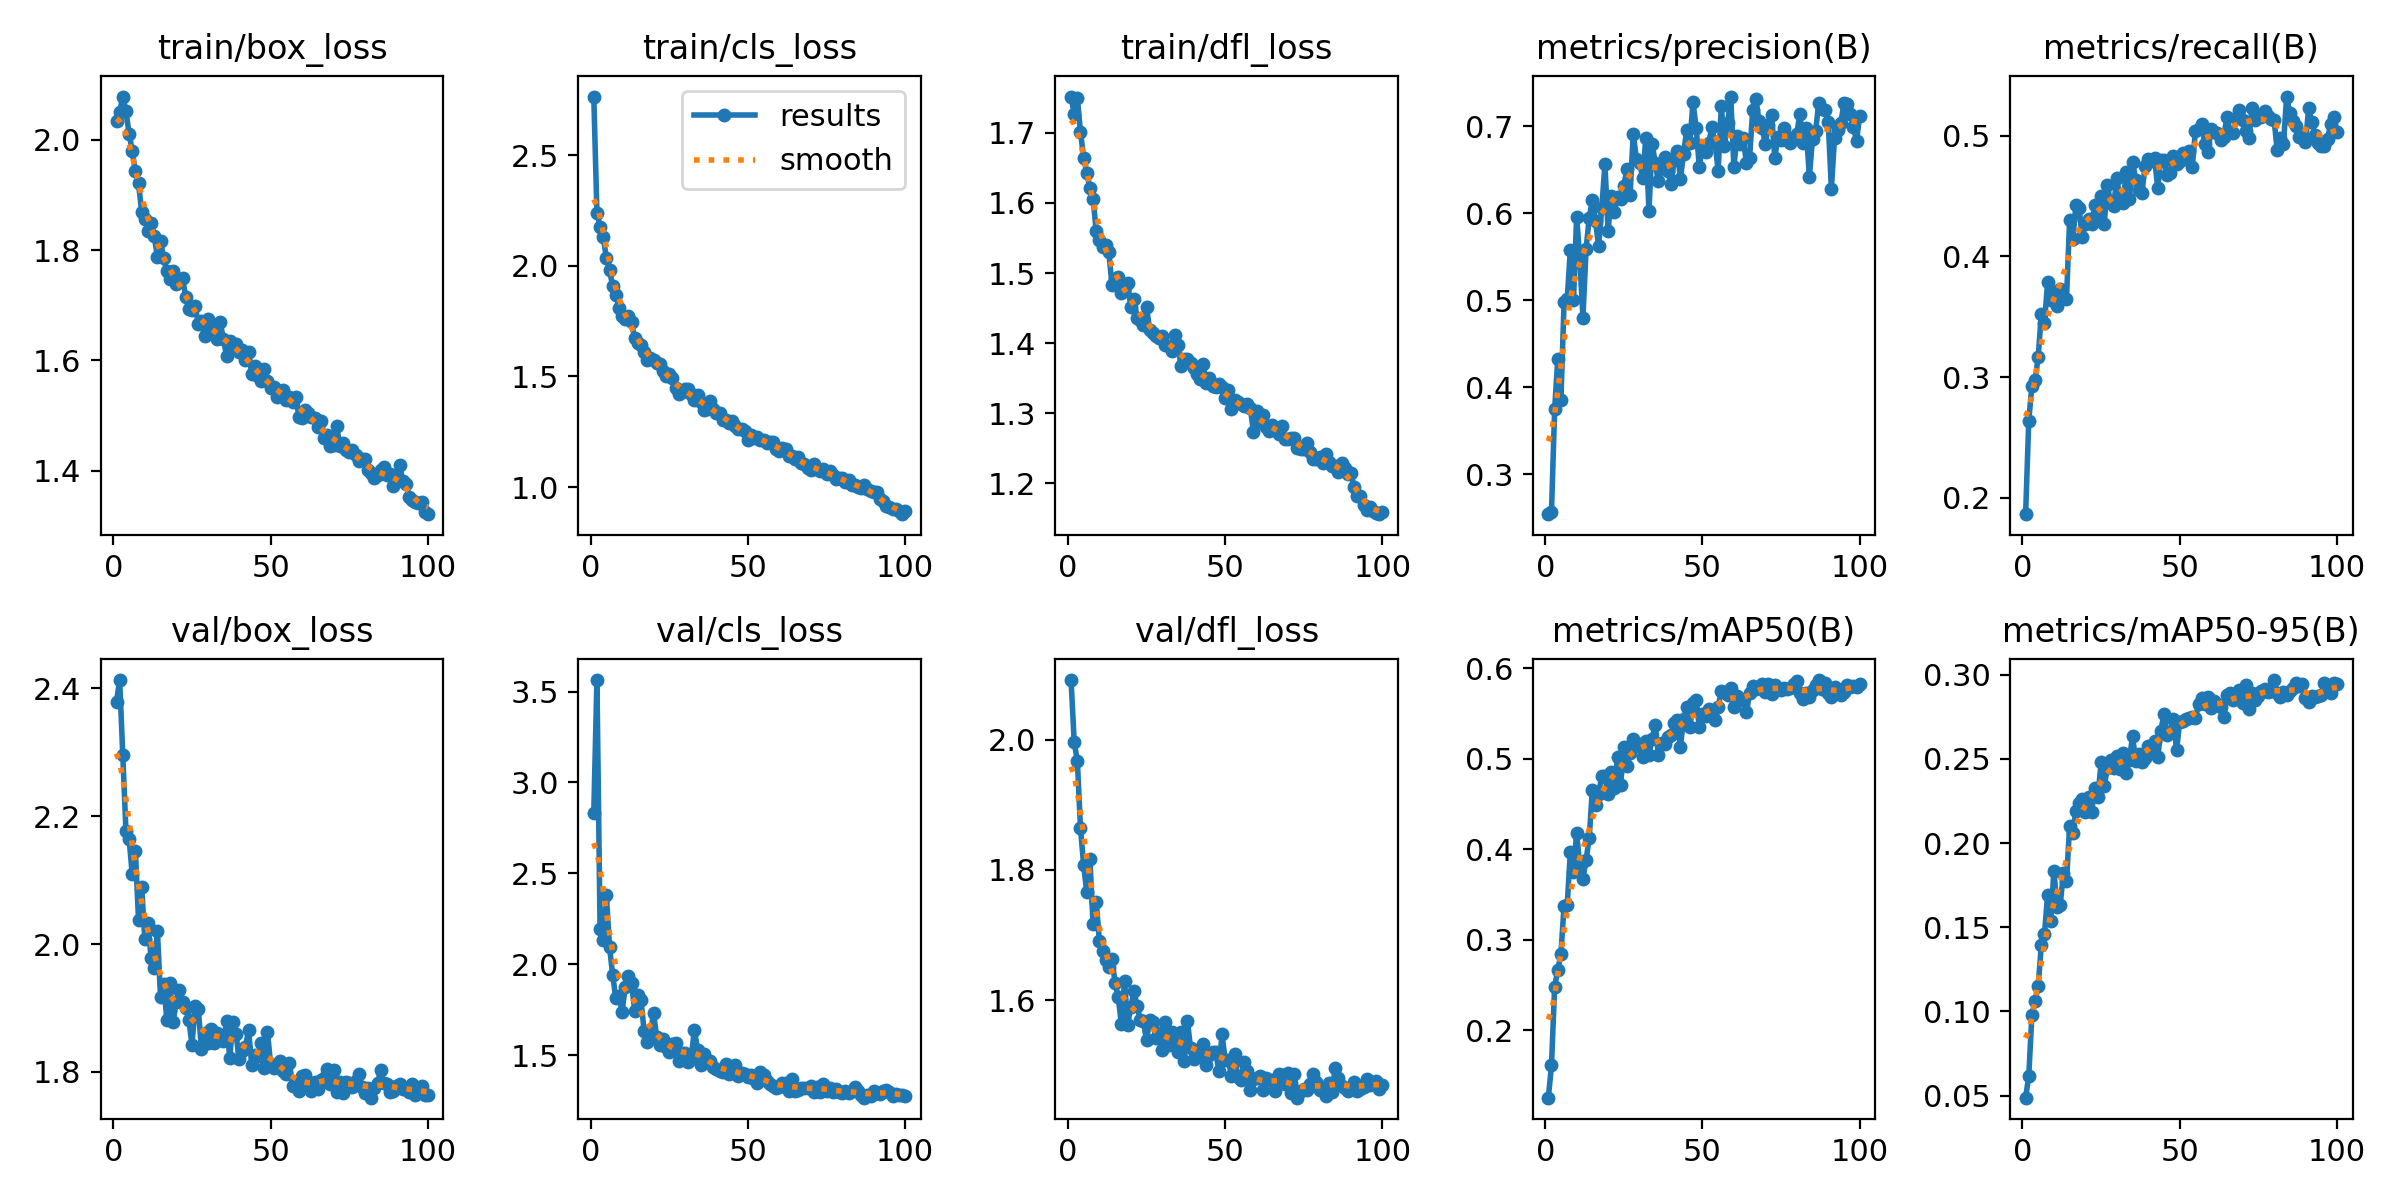

confusion_matrix.png


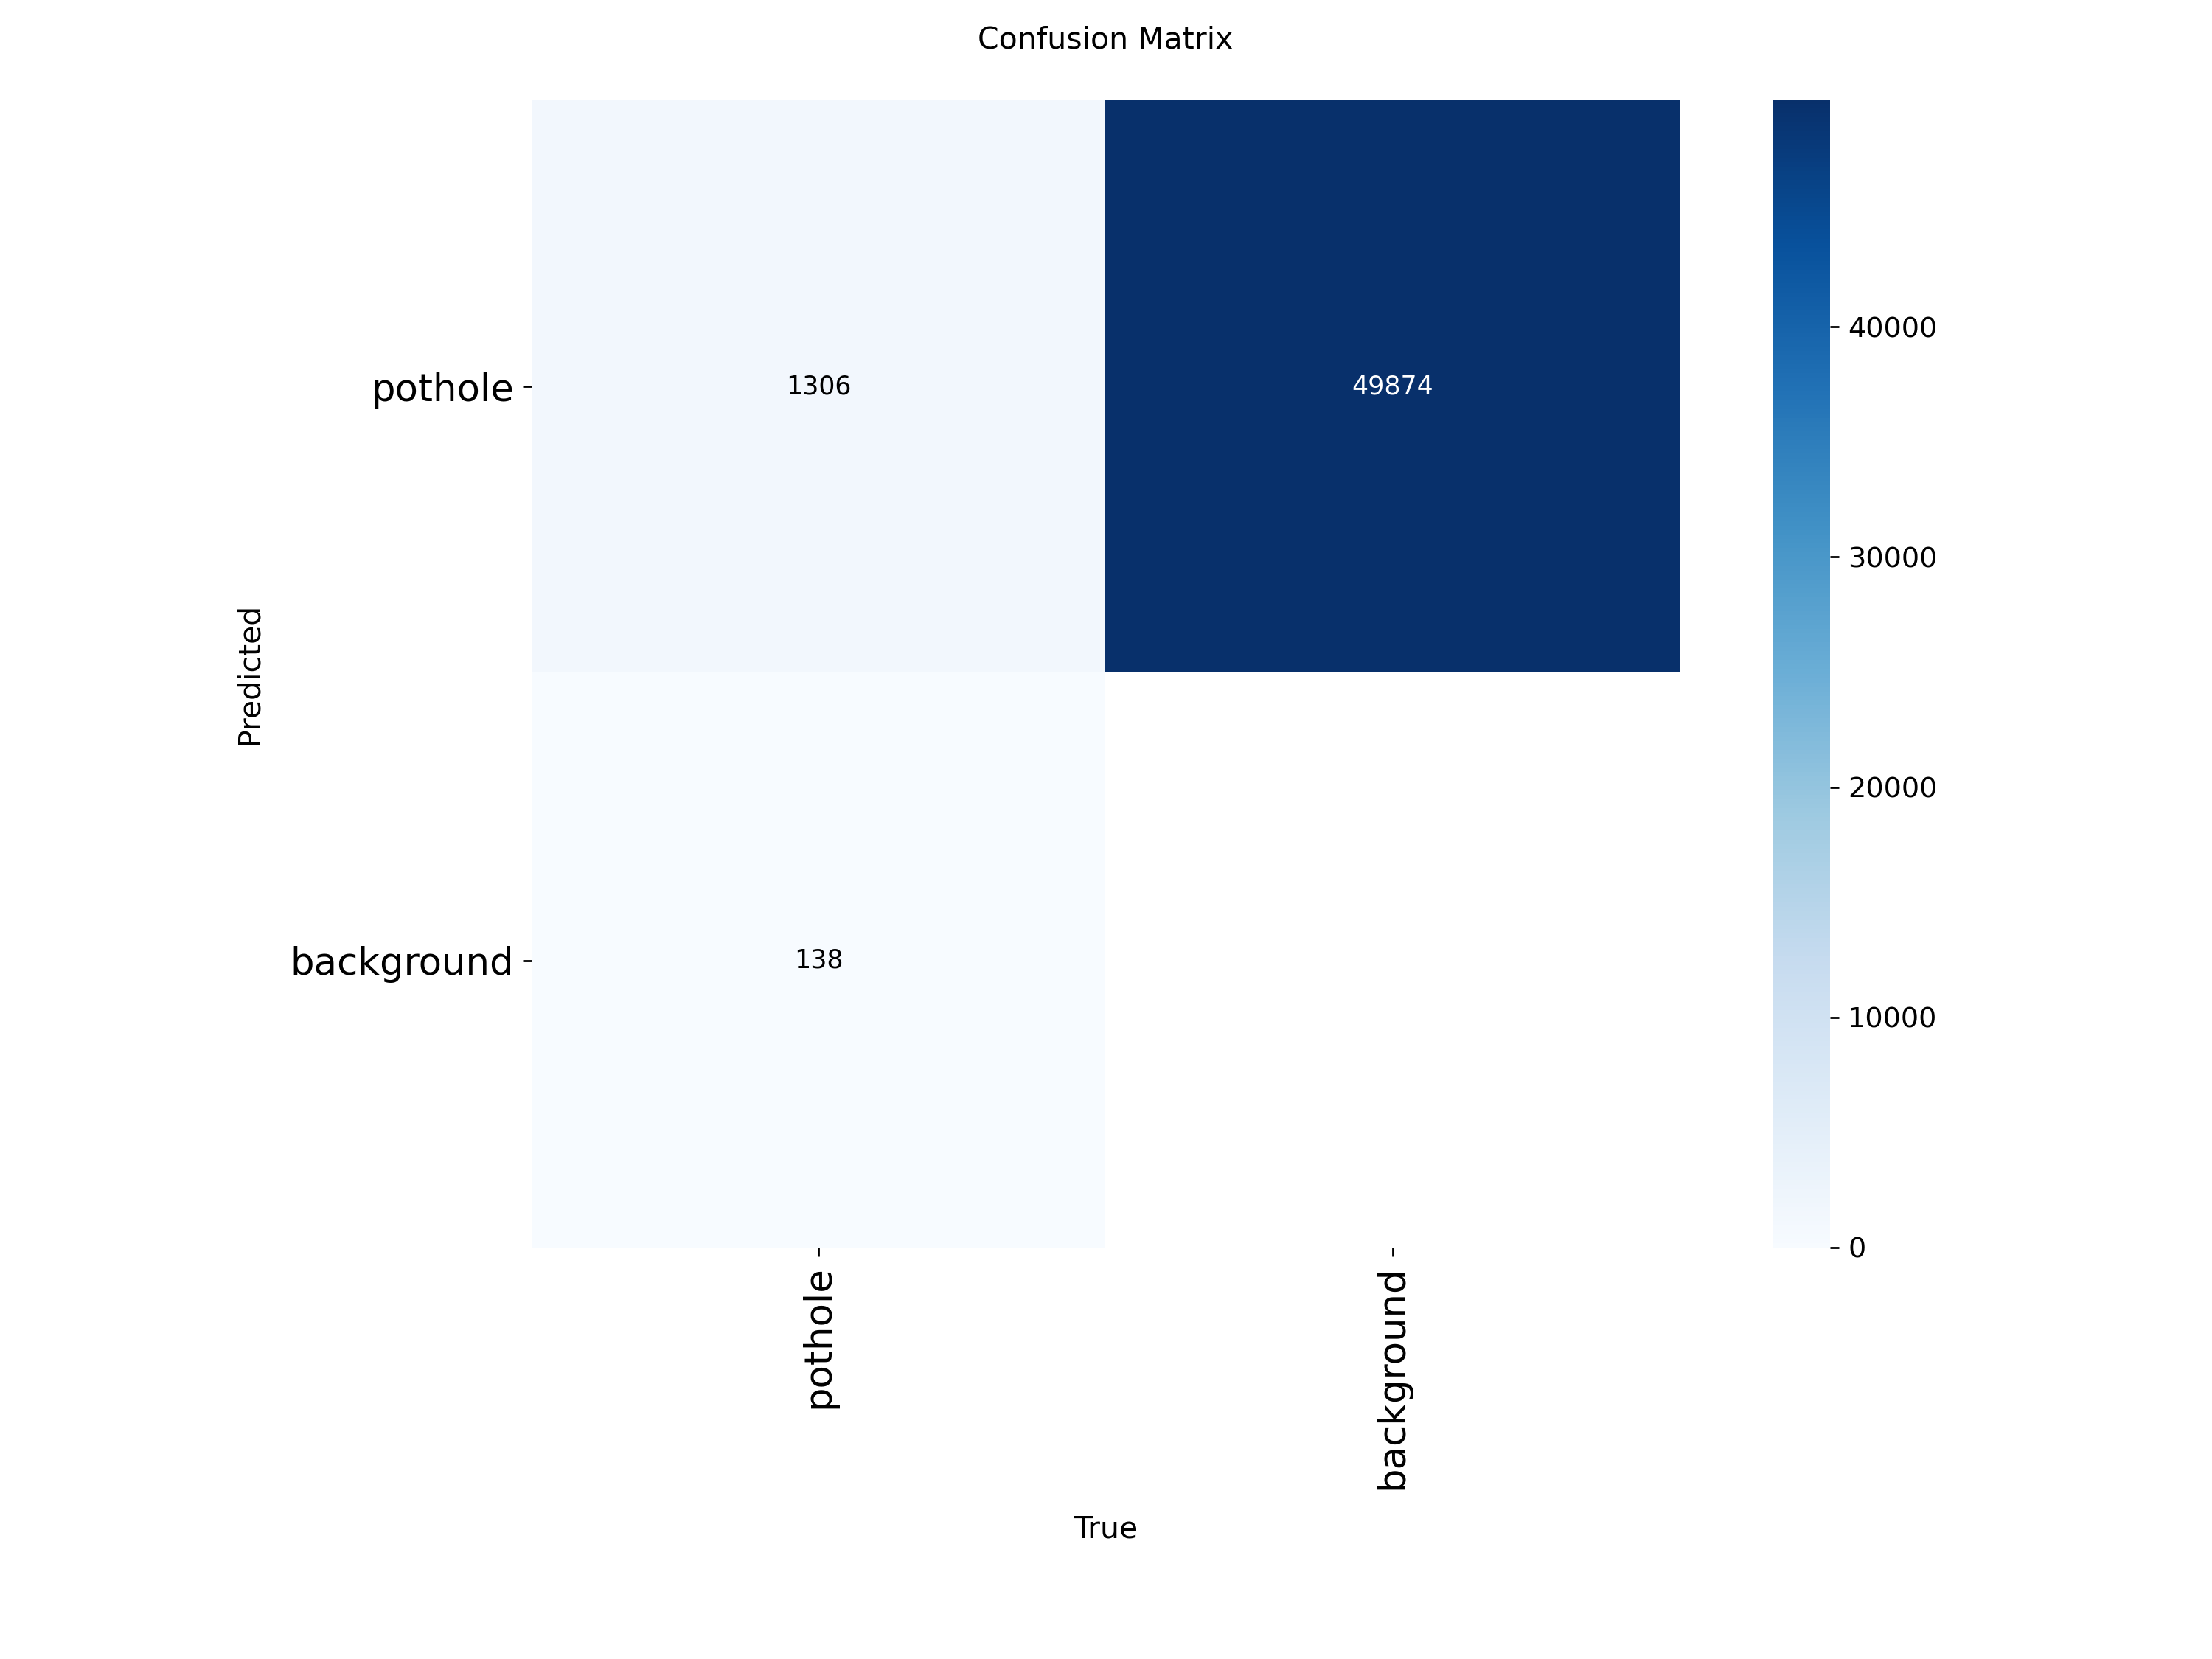

confusion_matrix_normalized.png


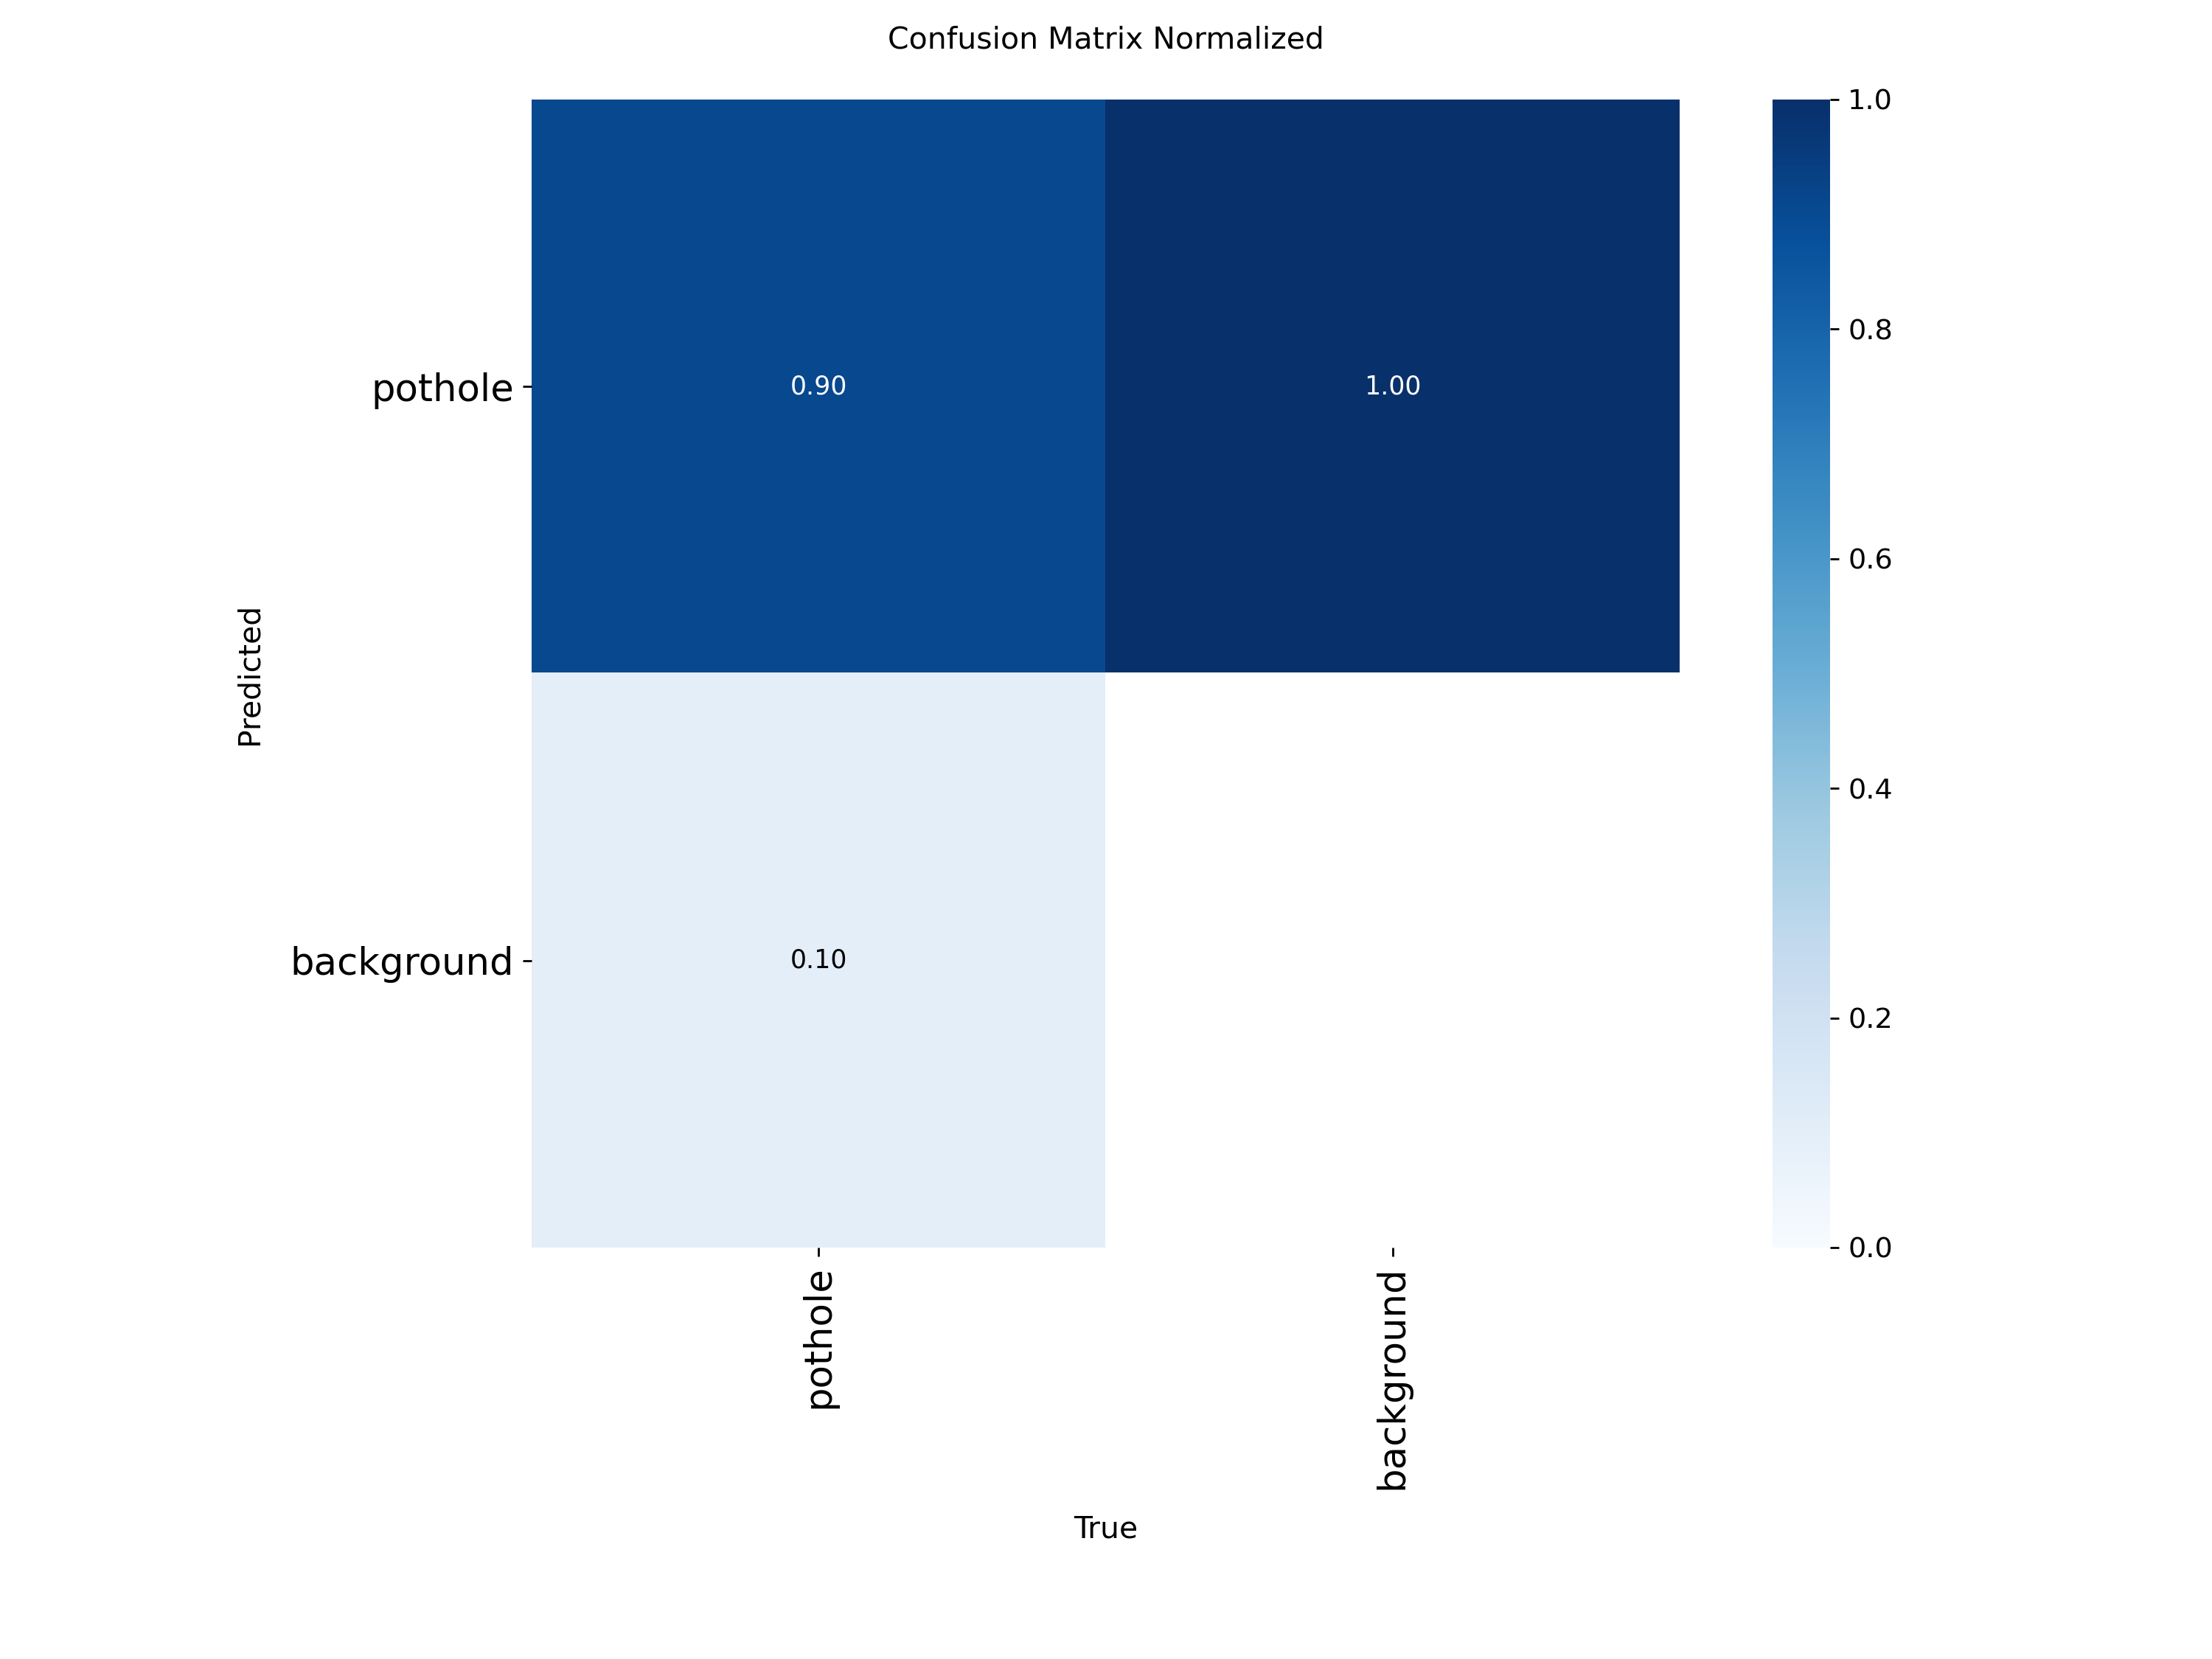

BoxF1_curve.png


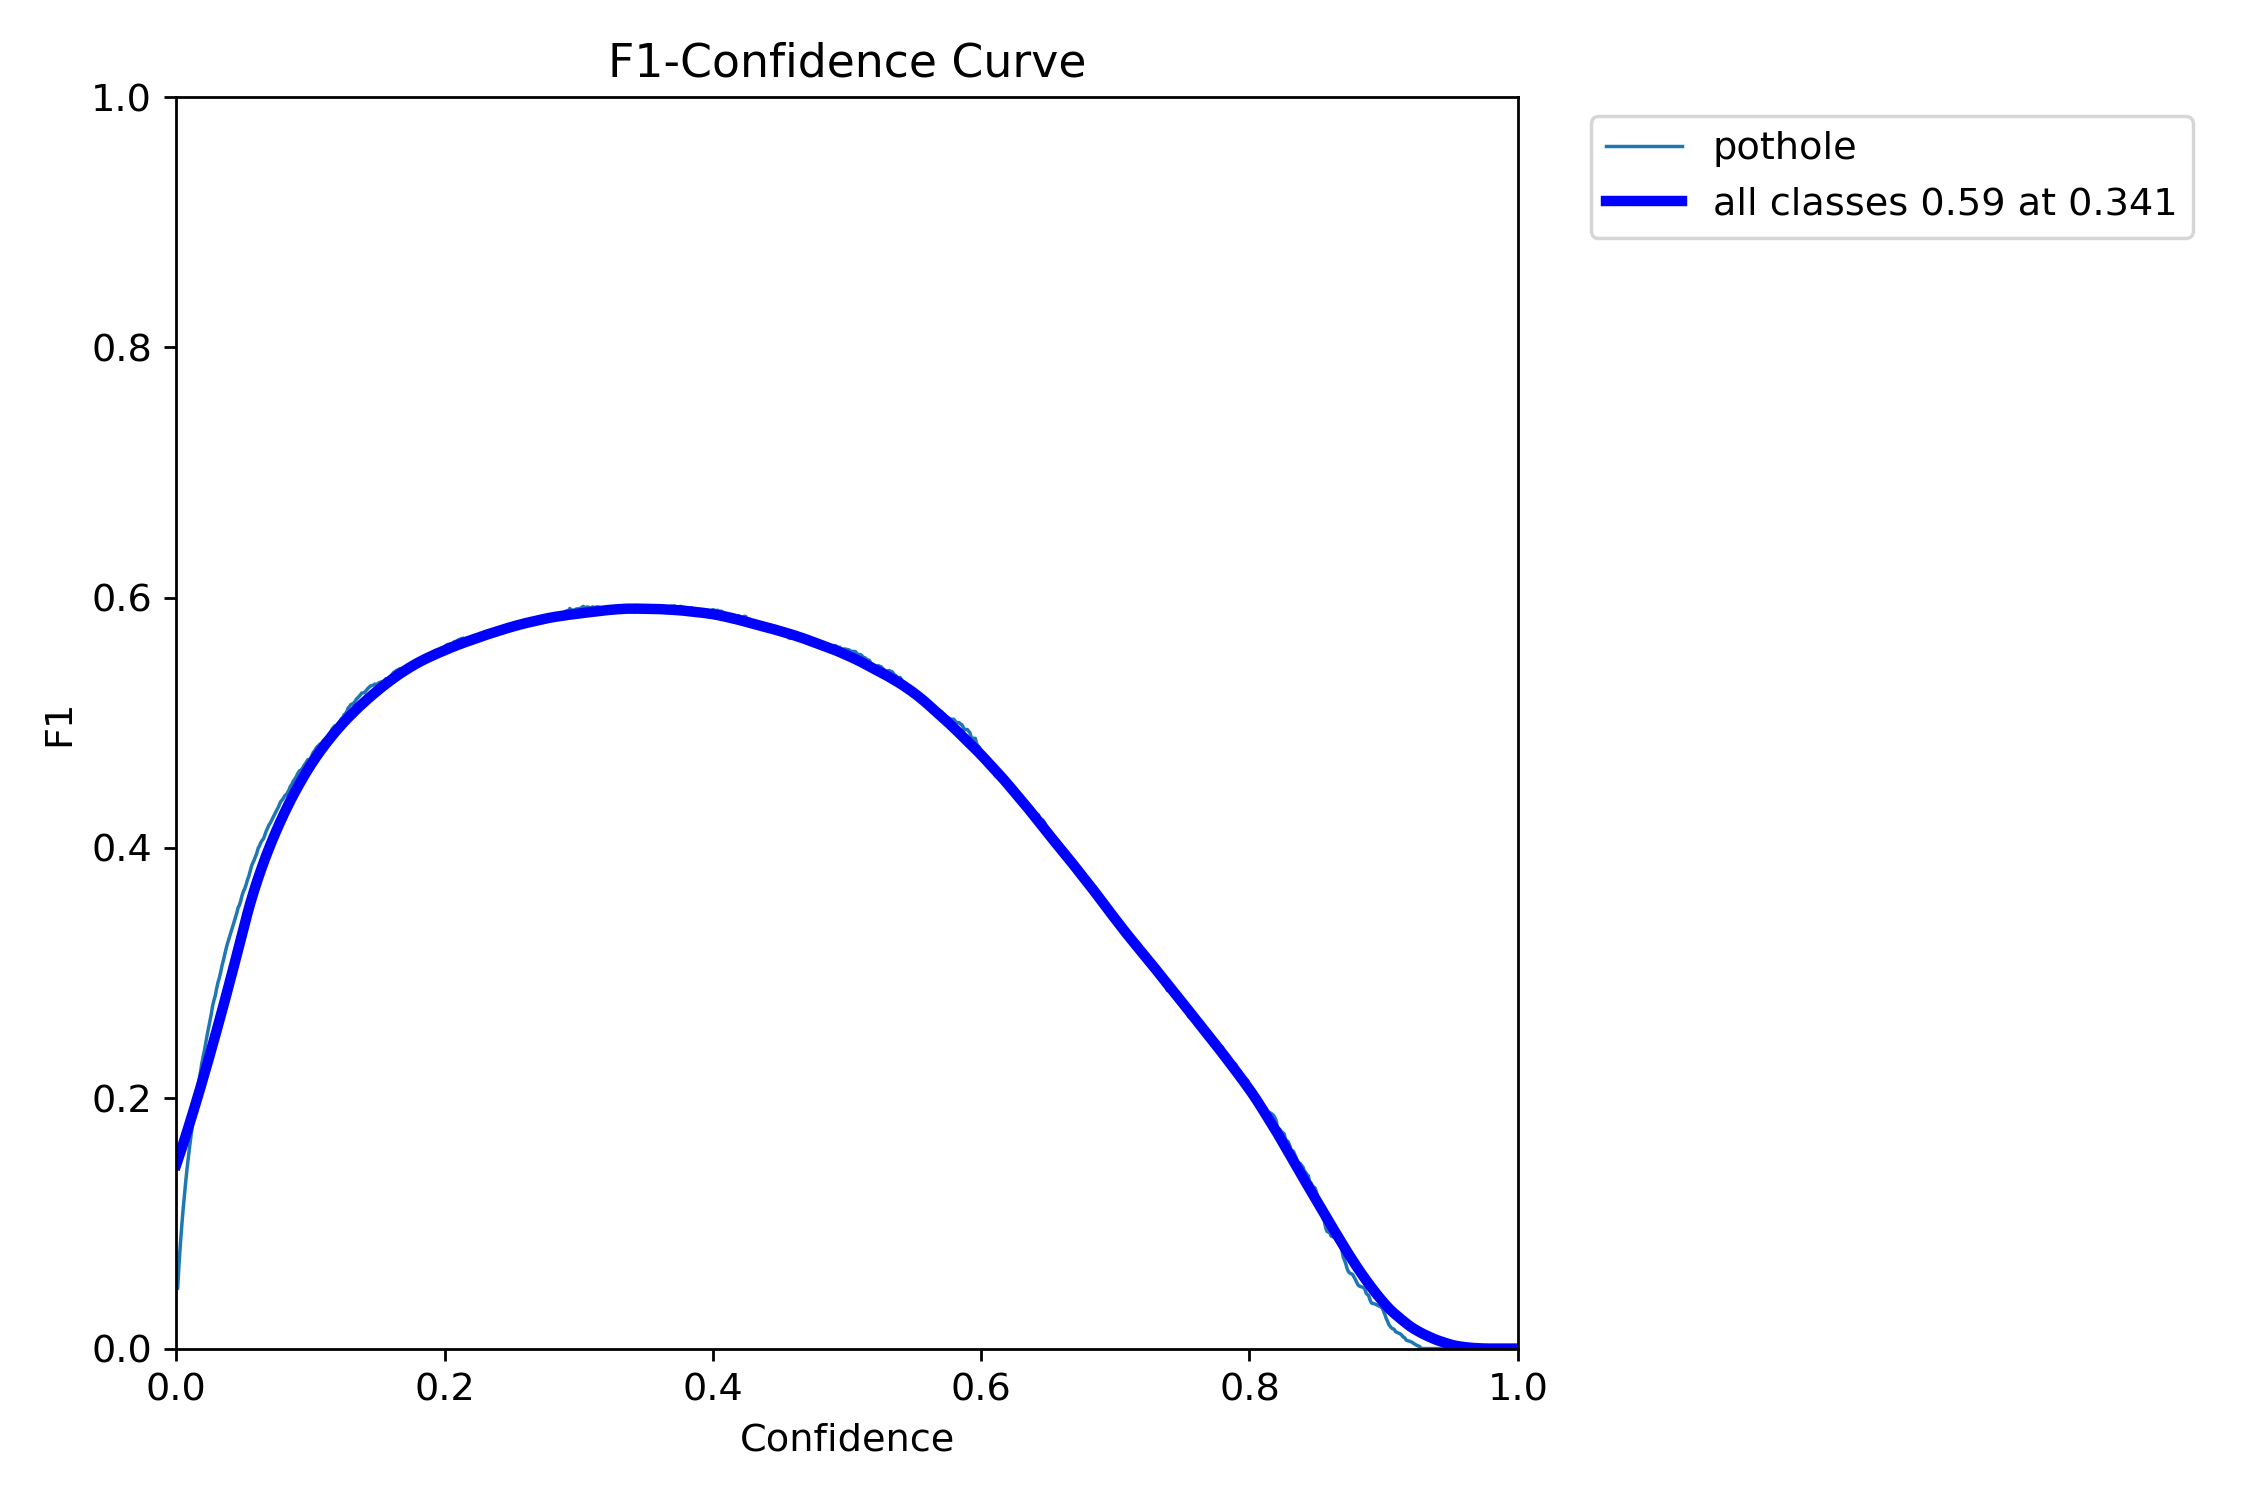

BoxP_curve.png


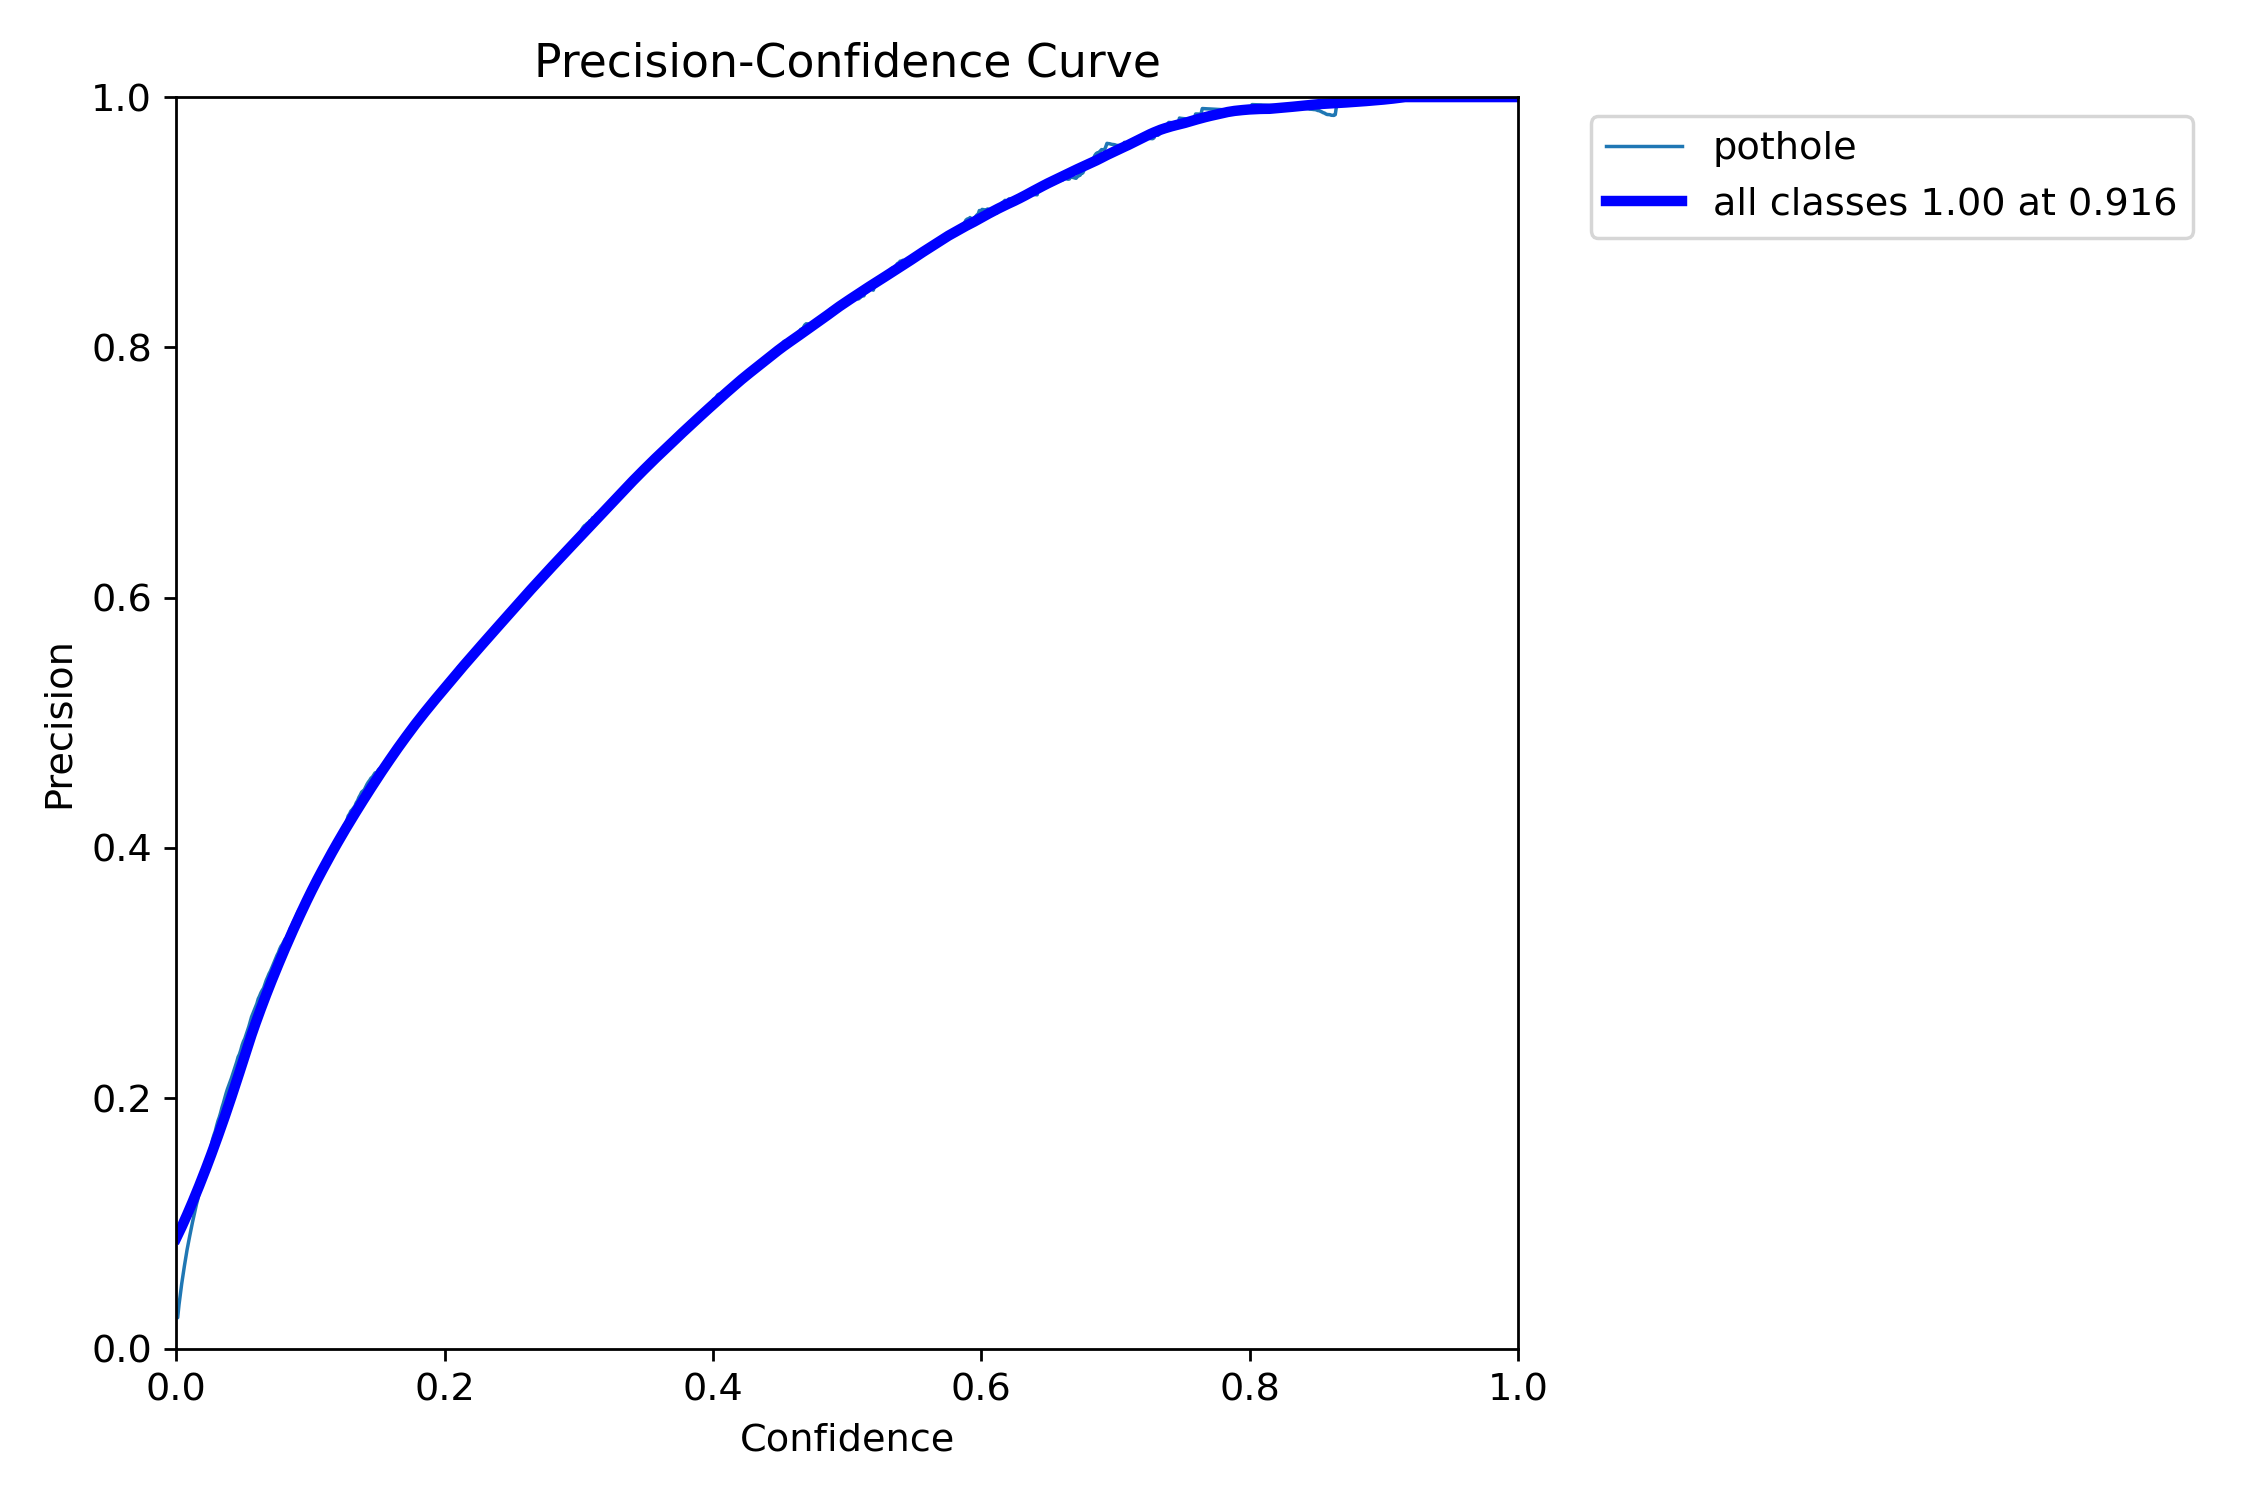

BoxR_curve.png


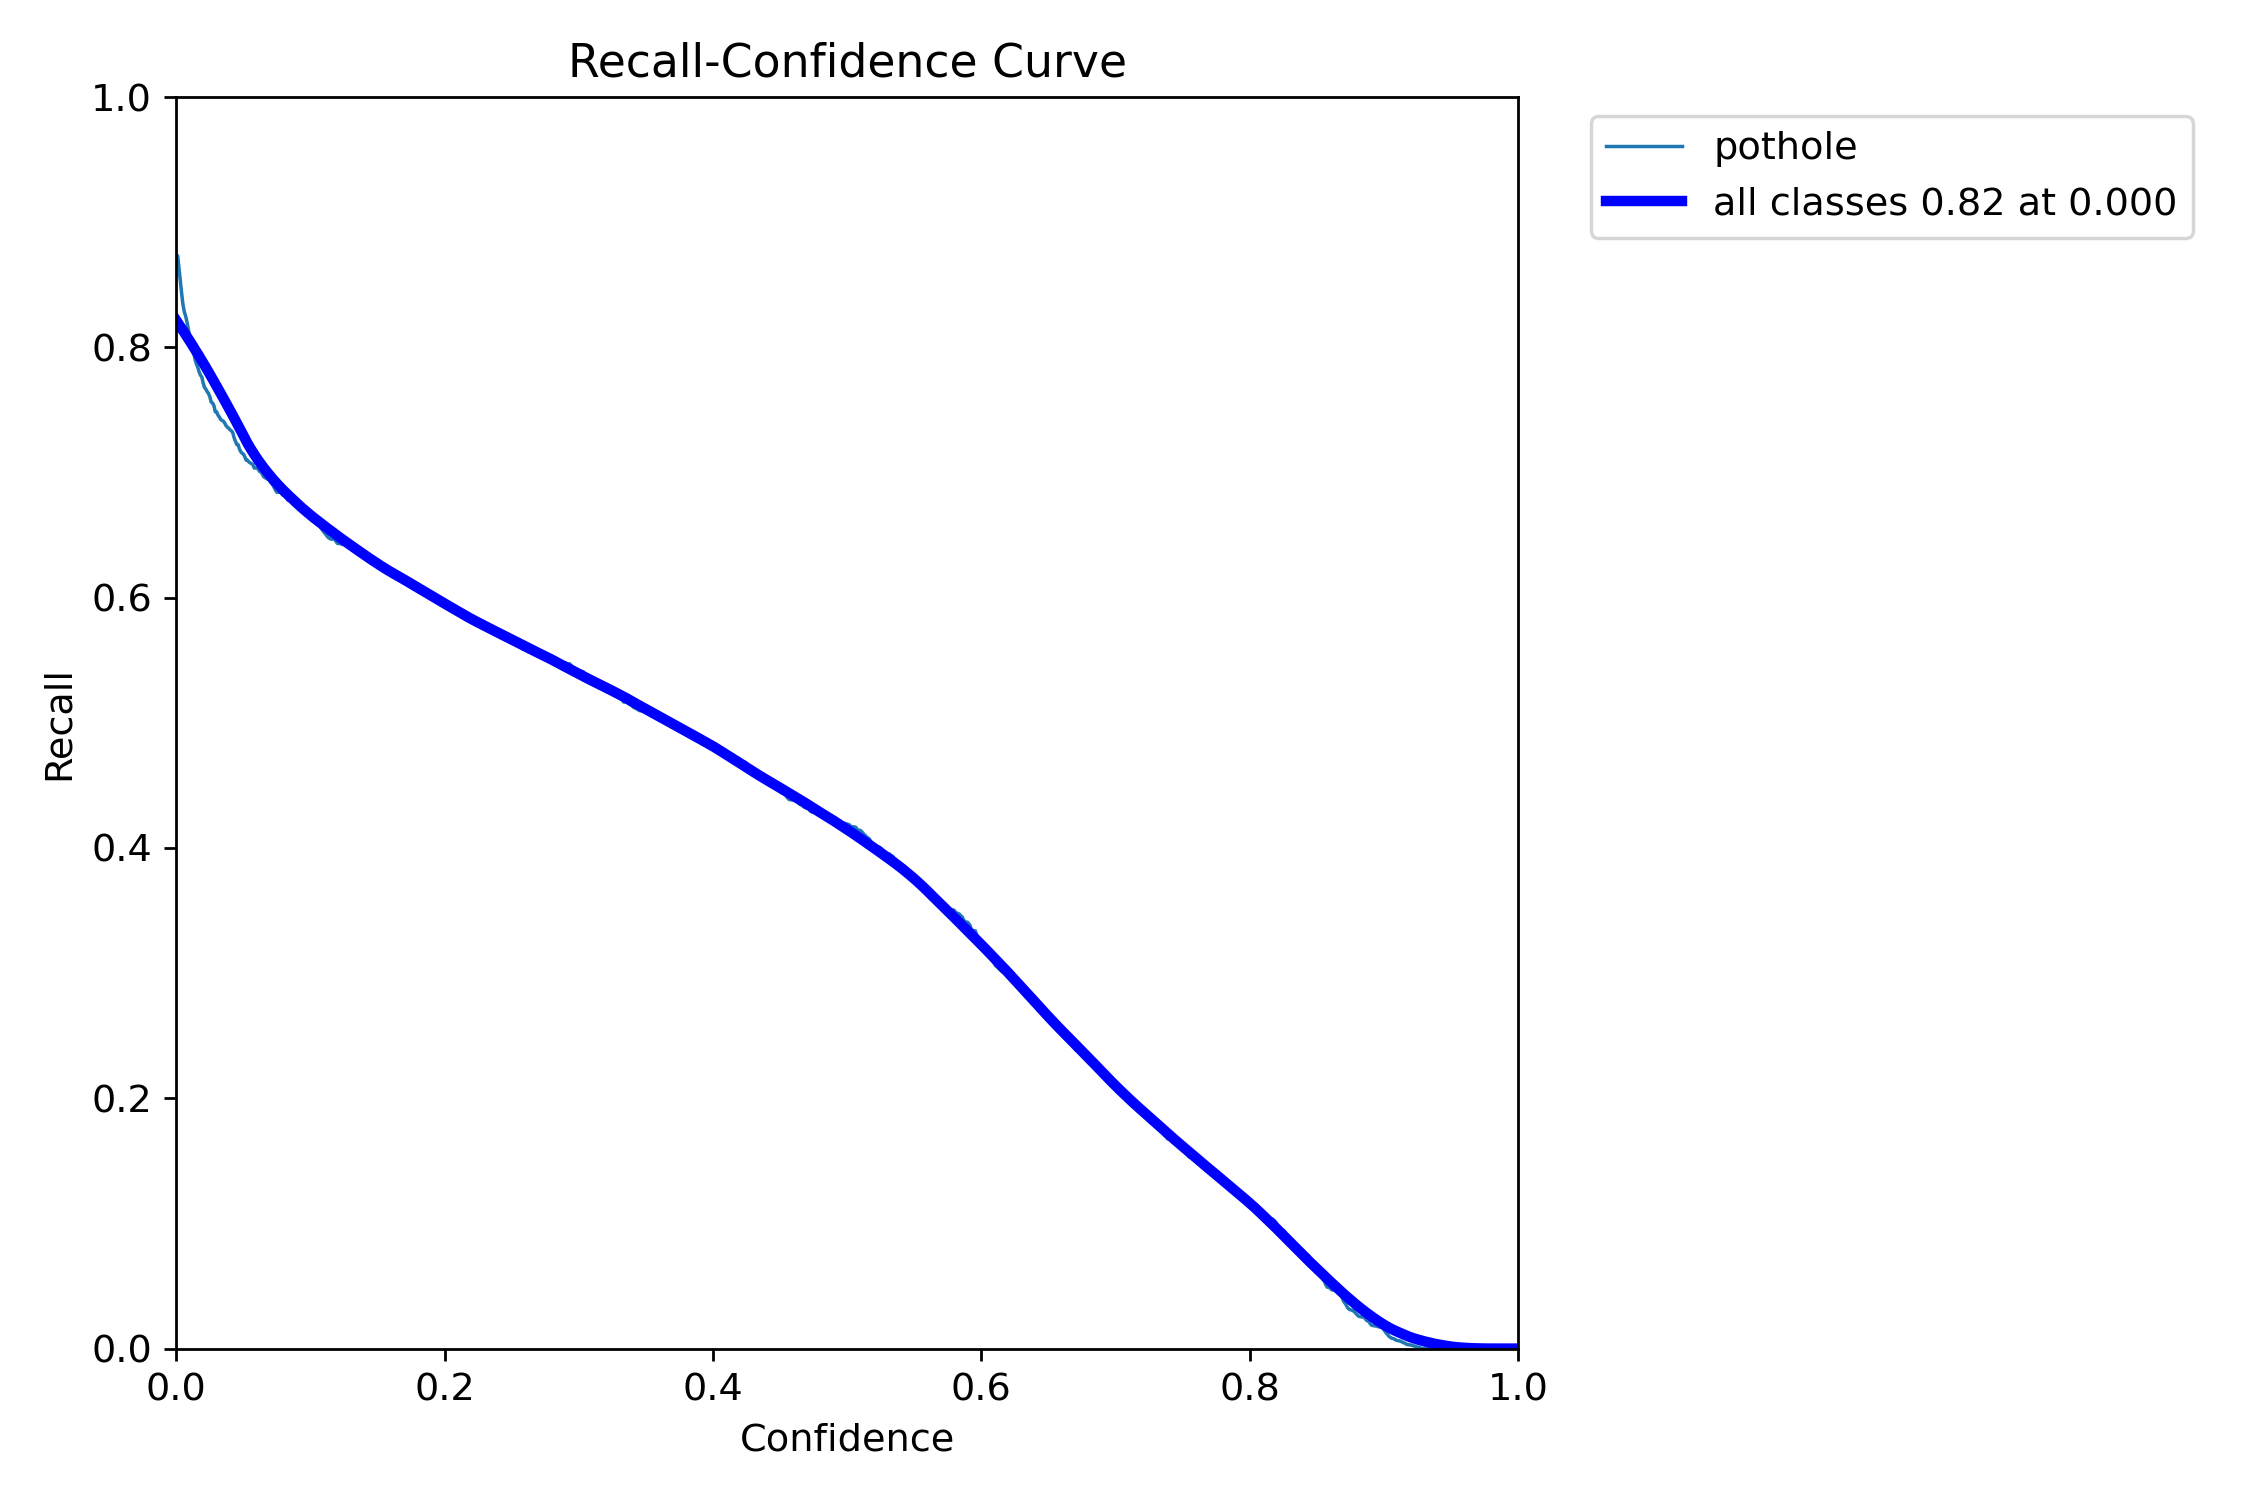

BoxPR_curve.png


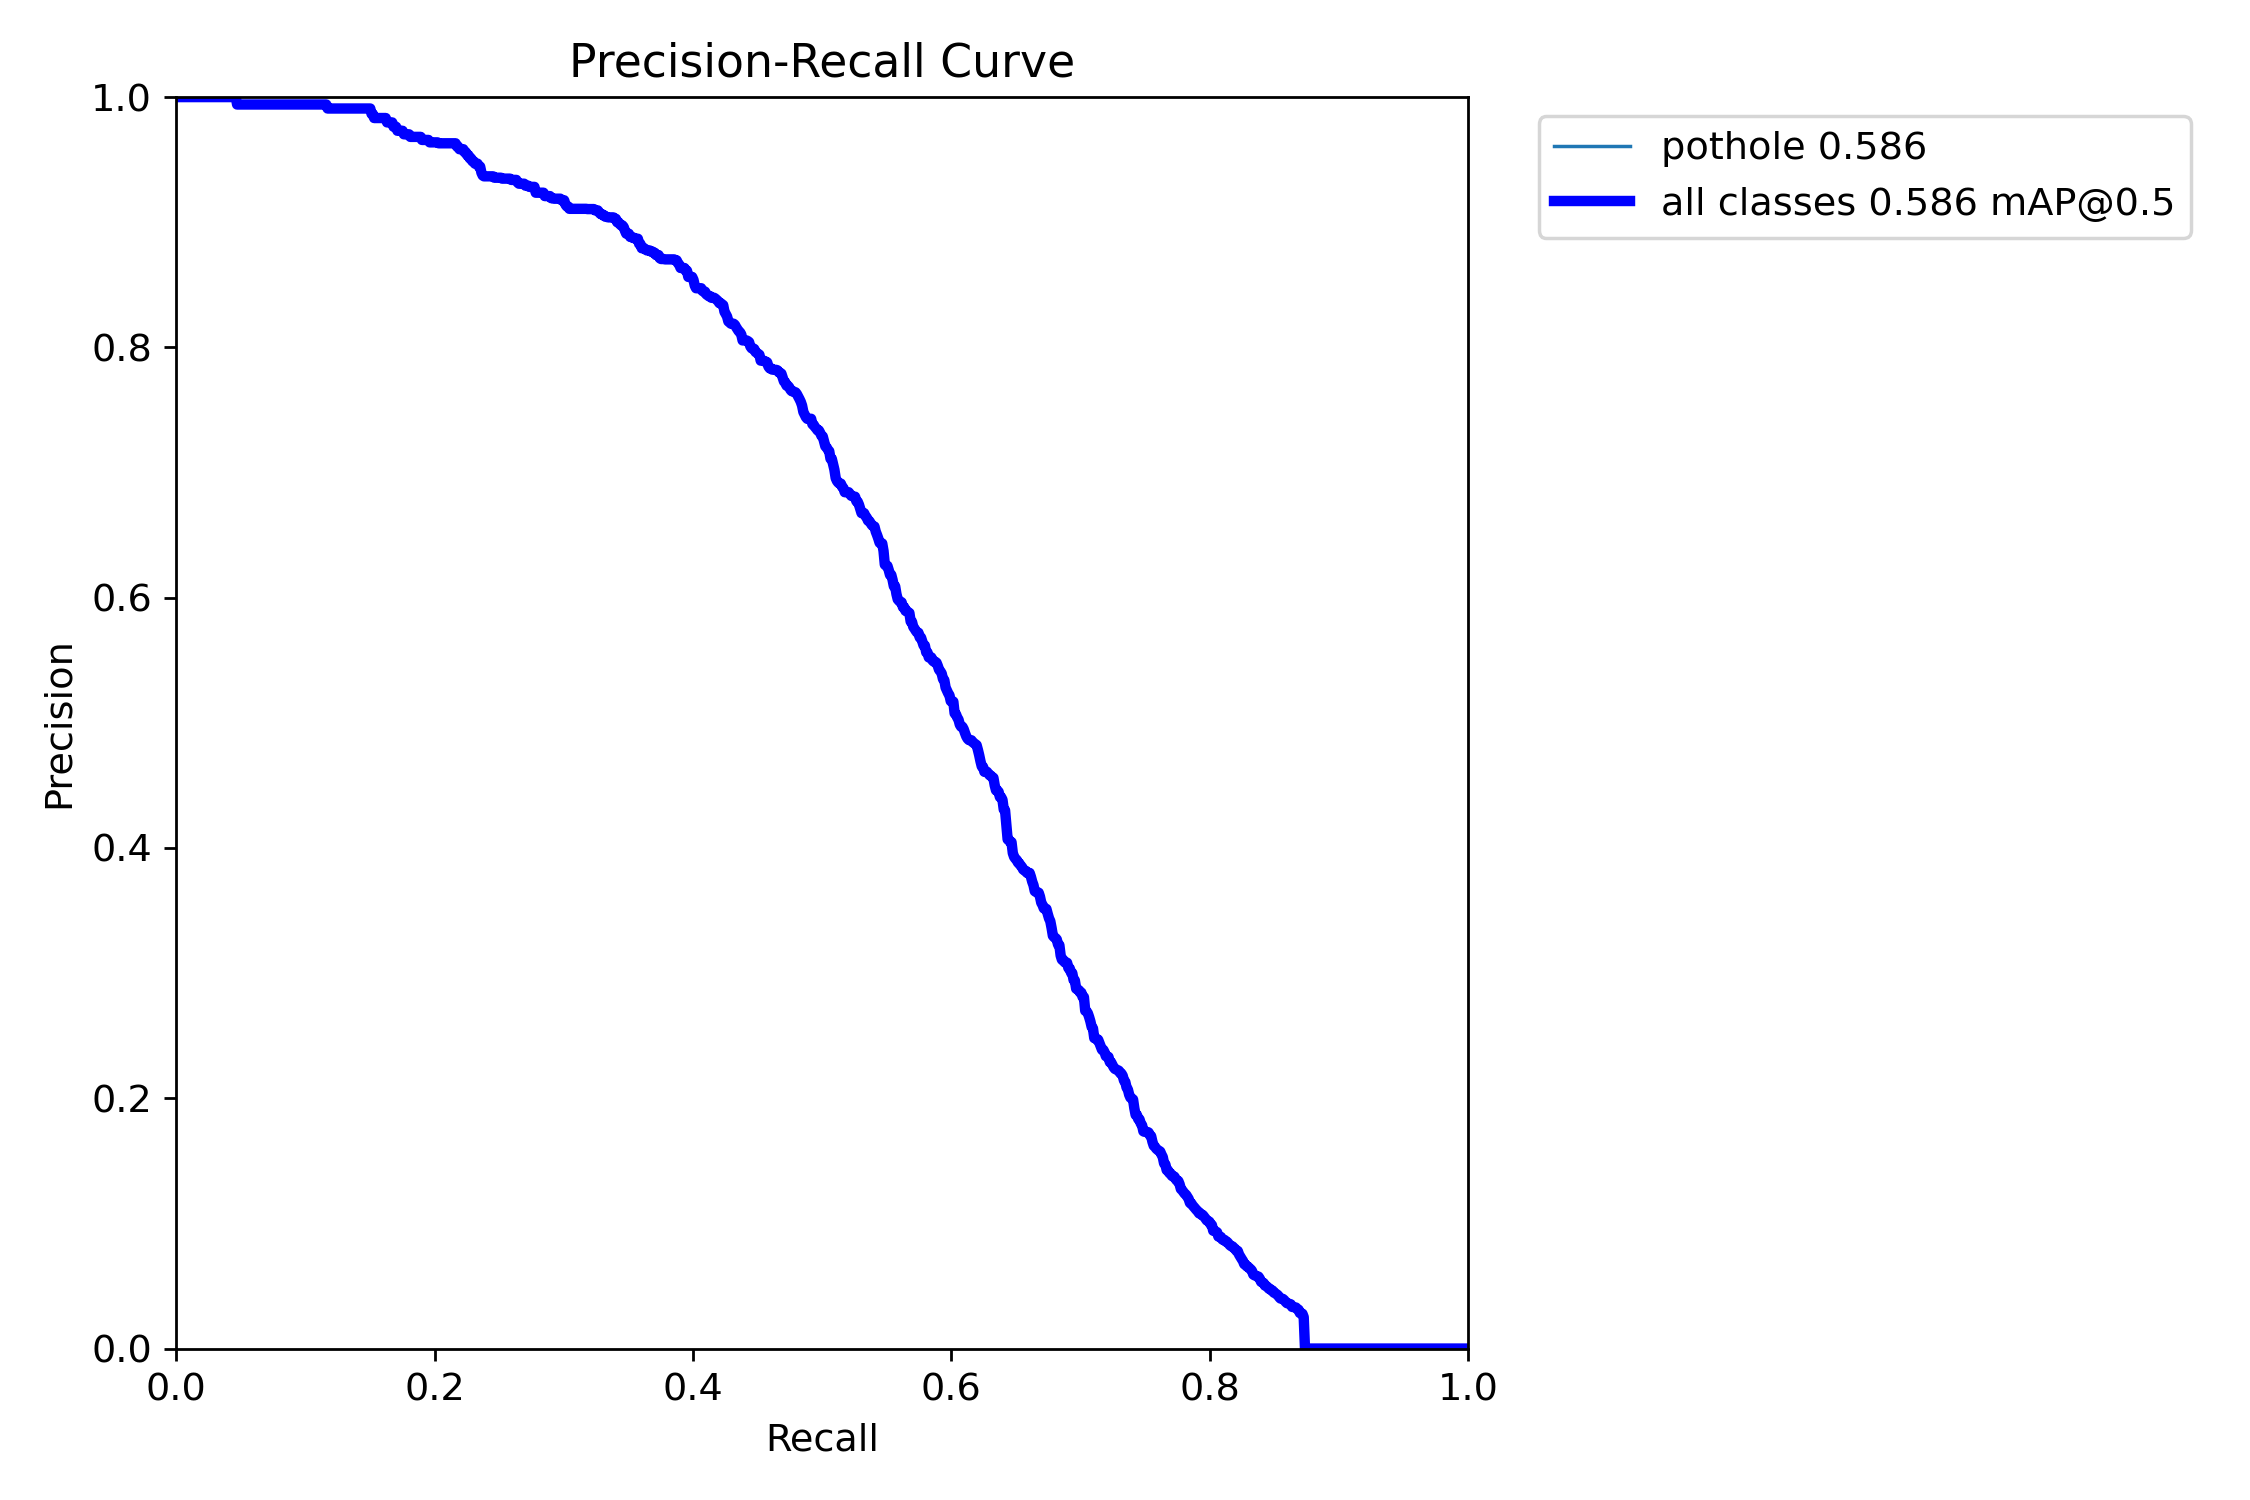

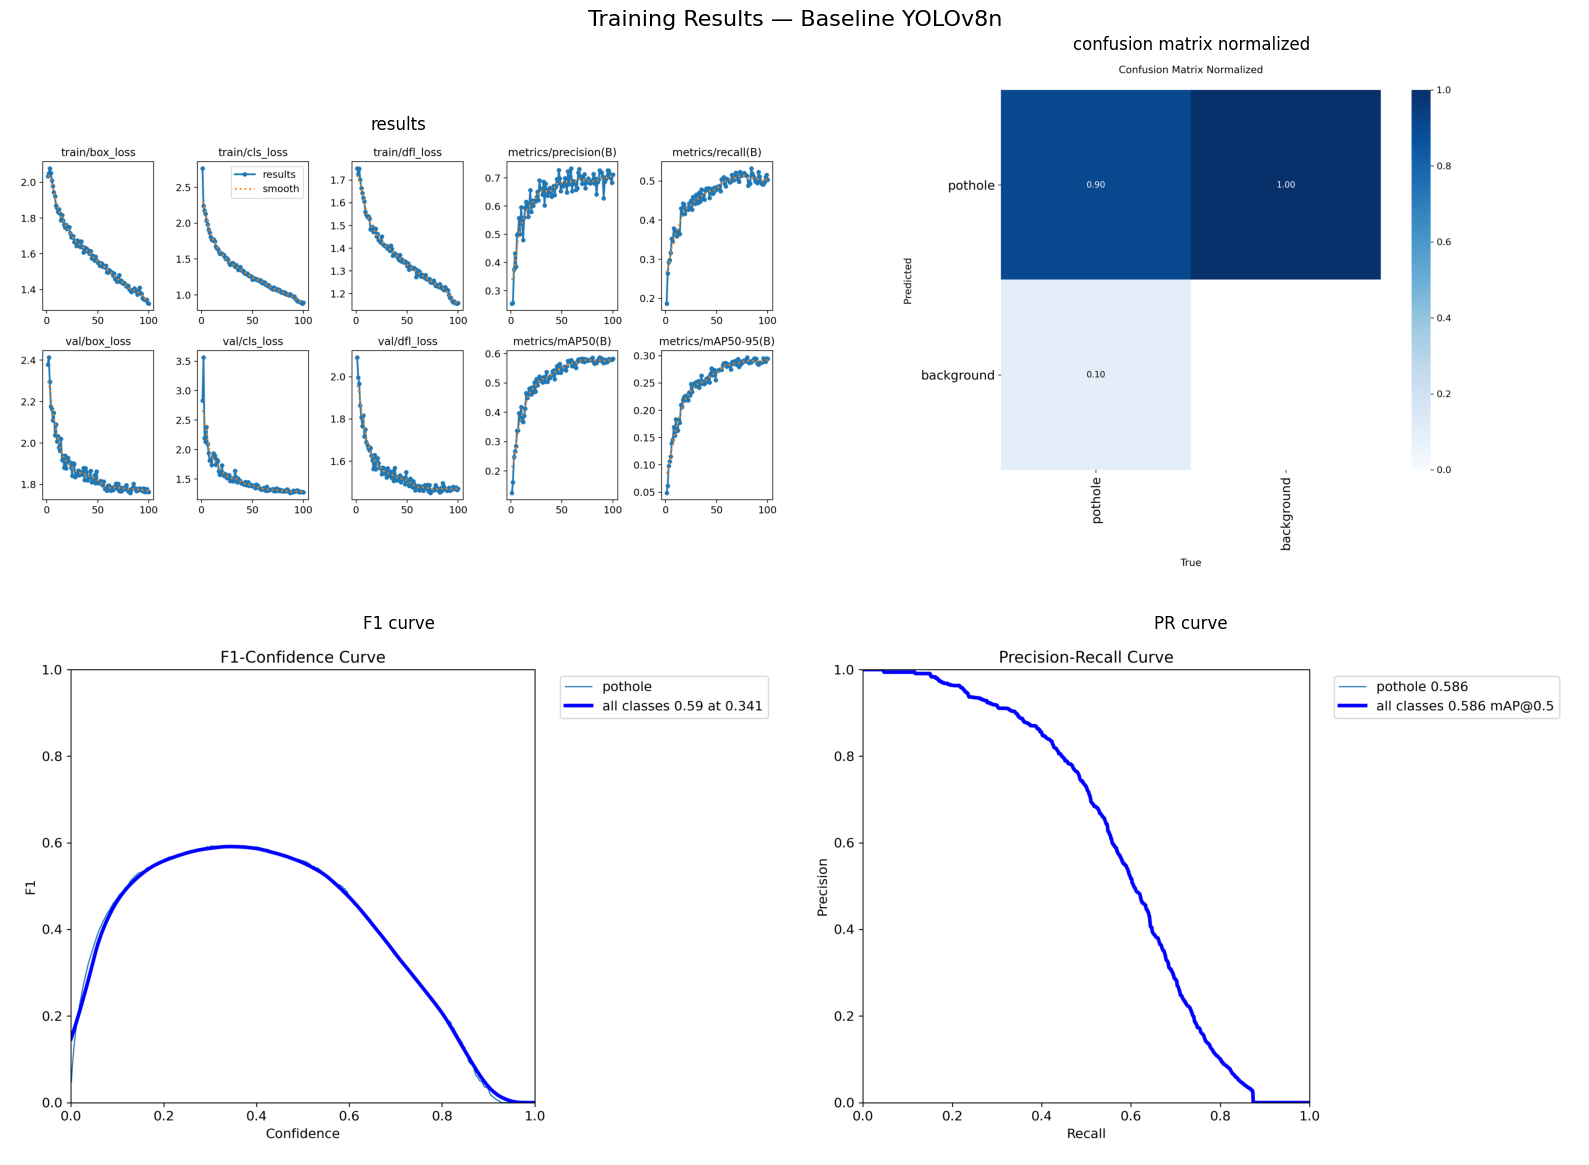

Combined summary saved to: /content/nighttime-pothole-detection/training_summary.png


In [ ]:
# ============================================================
# CELL 8: Display Training Curves
# ============================================================
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, Image as IPImage

# Directory containing YOLO training results
results_dir = Path(OUTPUT_DIR) / "baseline"

# Check whether training results exist
if not results_dir.exists():
    raise FileNotFoundError(
        f"Training results directory not found: {results_dir}\n"
        "Please run Cell 7 (training) first."
    )

def find_plot(name):
    """Newer Ultralytics saves curves as BoxF1_curve.png etc.; fall back to the old names."""
    p = results_dir / name
    if p.exists():
        return p
    alt = results_dir / name.replace("Box", "", 1)
    return alt if alt.exists() else p

plot_files = [
    "results.png",
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "BoxF1_curve.png",
    "BoxP_curve.png",
    "BoxR_curve.png",
    "BoxPR_curve.png",
]

# Display available individual plots
for pf in plot_files:
    img_path = find_plot(pf)
    if img_path.exists():
        print(pf)
        display(IPImage(filename=str(img_path), width=600))
    else:
        print(f"Plot not available: {pf}")

# Create a combined 2x2 summary
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

summary_plots = [
    "results.png",
    "confusion_matrix_normalized.png",
    "BoxF1_curve.png",
    "BoxPR_curve.png",
]

for ax, pf in zip(axes.flat, summary_plots):
    img_path = find_plot(pf)

    if img_path.exists():
        ax.imshow(plt.imread(img_path))
        ax.set_title(
            pf.replace(".png", "").replace("Box", "").replace("_", " "),
            fontsize=12
        )
    else:
        ax.text(
            0.5, 0.5,
            f"{pf}\nNot available",
            ha="center", va="center"
        )

    ax.axis("off")

plt.suptitle("Training Results — Baseline YOLOv8n", fontsize=16)
plt.tight_layout()

summary_path = Path(OUTPUT_DIR) / "training_summary.png"
plt.savefig(summary_path, dpi=150, bbox_inches="tight")
plt.show()

print(f"Combined summary saved to: {summary_path}")

In [ ]:

# ============================================================
# CELL 9: Model Evaluation
# ============================================================
from ultralytics import YOLO
from pathlib import Path
import yaml

# Load best checkpoint
best_weights = Path(results_dir) / "weights" / "best.pt"

if not best_weights.exists():
    raise FileNotFoundError(
        f"Best model weights not found: {best_weights}\n"
        "Please complete Cell 7 training first."
    )

best_model = YOLO(str(best_weights))

# Read dataset configuration
with open(data_yaml_path, "r") as f:
    cfg = yaml.safe_load(f)

def print_metrics(metrics, title):
    print("\n" + "=" * 60)
    print(title)
    print("=" * 60)

    metric_names = [
        ("Precision", "metrics/precision(B)"),
        ("Recall", "metrics/recall(B)"),
        ("mAP@0.5", "metrics/mAP50(B)"),
        ("mAP@0.5:0.95", "metrics/mAP50-95(B)"),
    ]

    for label, key in metric_names:
        value = metrics.get(key)
        if value is not None:
            print(f"  {label:<18} {value:.4f}")
        else:
            print(f"  {label:<18} N/A")

    print("=" * 60)

# Evaluate on validation set
val_results = best_model.val(
    data=str(data_yaml_path),
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    split="val",
    plots=True,
    save_json=True,
)

print_metrics(
    val_results.results_dict,
    "EVALUATION RESULTS — Baseline YOLOv8"
)

# Evaluate on test set if it is defined in data.yaml
if cfg.get("test"):
    print("\nEvaluating on TEST set...")

    test_results = best_model.val(
        data=str(data_yaml_path),
        imgsz=IMG_SIZE,
        batch=BATCH_SIZE,
        device=DEVICE,
        split="test",
        plots=True,
    )

    print_metrics(
        test_results.results_dict,
        "TEST RESULTS — Baseline YOLOv8"
    )
else:
    print("\nNo test split defined in data.yaml; skipping test evaluation.")


Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2299.8±256.3 MB/s, size: 182.9 KB)
val: Scanning /content/pothole_only/valid/labels.cache... 533 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 533/533 131.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 67/67 4.4it/s 15.1s
                   all        533       1444      0.699      0.509      0.585      0.298
Speed: 2.5ms preprocess, 7.5ms inference, 0.0ms loss, 3.0ms postprocess per image
Saving /content/runs/detect/val/predictions.json...

Evaluating faster-coco-eval mAP...
requirements: Ultralytics requirement ['faster-coco-eval>=1.6.7'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 2 packages in 315ms
Prepared 1 package in 61ms
Installed 1 package in 1ms

Evaluation split: test
Image directory: /content/pothole_only/test/images
Images selected: 12
Results saved to /content/nighttime-pothole-detection/predictions


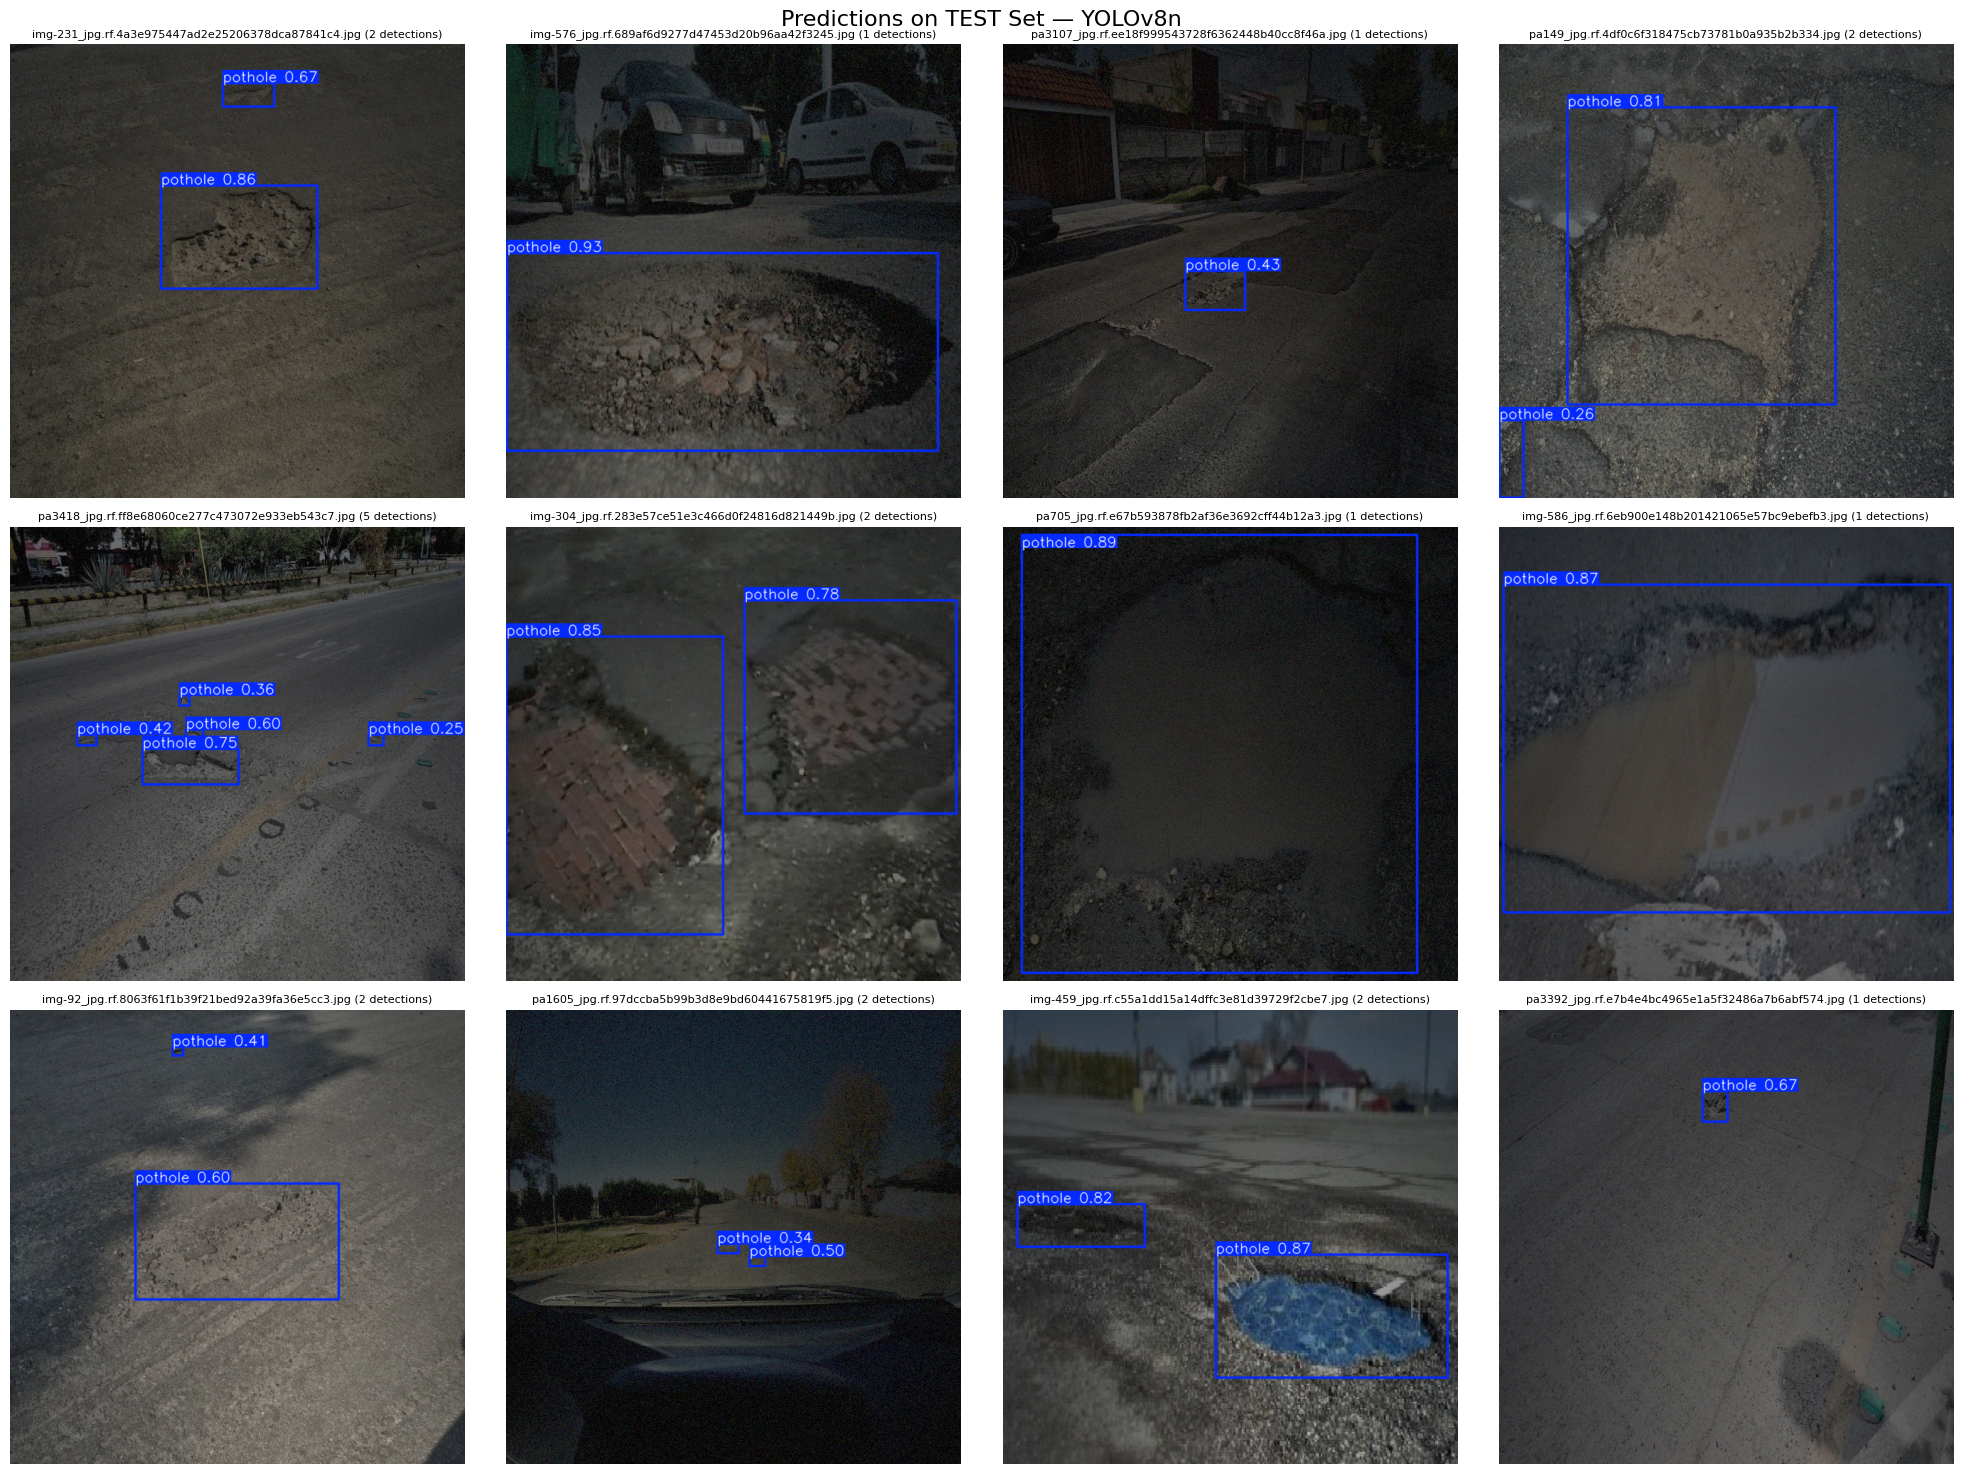

Prediction grid saved to: /content/nighttime-pothole-detection/prediction_samples.png
Annotated images saved in: /content/nighttime-pothole-detection/predictions


In [ ]:

# ============================================================
# CELL 10: Visualize Predictions on Validation/Test Images
# ============================================================

from pathlib import Path
import random
import yaml
import matplotlib.pyplot as plt
from IPython.display import display

# Supported image formats
img_exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

# Load dataset configuration
with open(data_yaml_path, "r") as f:
    cfg = yaml.safe_load(f)

# Select test split if configured; otherwise validation split
eval_split = "test" if cfg.get("test") else "val"
eval_img_dir = Path(cfg[eval_split])

# Resolve relative paths if needed
if not eval_img_dir.is_absolute():
    dataset_base = Path(cfg.get("path", Path(data_yaml_path).parent))
    eval_img_dir = dataset_base / eval_img_dir

if not eval_img_dir.exists():
    raise FileNotFoundError(
        f"Image directory not found: {eval_img_dir}\n"
        "Check the paths in data.yaml."
    )

# Collect images
eval_imgs = [
    f for f in eval_img_dir.iterdir()
    if f.is_file() and f.suffix.lower() in img_exts
]

if not eval_imgs:
    raise FileNotFoundError(
        f"No images found in {eval_img_dir}. "
        "Check that the selected path points to an images directory."
    )

# Randomly select up to 12 images
random.seed(42)
sample_eval = random.sample(eval_imgs, min(12, len(eval_imgs)))

print(f"Evaluation split: {eval_split}")
print(f"Image directory: {eval_img_dir}")
print(f"Images selected: {len(sample_eval)}")

# Run inference
predictions = best_model.predict(
    source=[str(p) for p in sample_eval],
    imgsz=IMG_SIZE,
    conf=CONF_THRESH,
    iou=IOU_THRESH,
    device=DEVICE,
    save=True,
    project=str(OUTPUT_DIR),
    name="predictions",
    exist_ok=True,
    verbose=False,
)

# Display predictions in a grid
fig, axes = plt.subplots(3, 4, figsize=(20, 15))
axes = axes.flatten()

for ax in axes:
    ax.axis("off")

for ax, pred in zip(axes, predictions):
    # Ultralytics returns an annotated BGR image
    annotated = pred.plot()
    ax.imshow(annotated[:, :, ::-1])
    ax.axis("off")

    n_det = len(pred.boxes) if pred.boxes is not None else 0
    ax.set_title(
        f"{Path(pred.path).name} ({n_det} detections)",
        fontsize=8
    )

plt.suptitle(
    f"Predictions on {eval_split.upper()} Set — YOLOv8{MODEL_SIZE}",
    fontsize=16
)
plt.tight_layout()

prediction_grid = Path(OUTPUT_DIR) / "prediction_samples.png"
plt.savefig(prediction_grid, dpi=150, bbox_inches="tight")
plt.show()

print(f"Prediction grid saved to: {prediction_grid}")
print(f"Annotated images saved in: {OUTPUT_DIR / 'predictions'}")


Evaluation images: /content/pothole_only/test/images
Ground-truth labels: /content/pothole_only/test/labels

ERROR ANALYSIS — TEST SET
Images analyzed:       50
True-positive boxes:   60
False-positive boxes:  30
False-negative boxes:  37
Sample precision:      0.6667
Sample recall:         0.6186


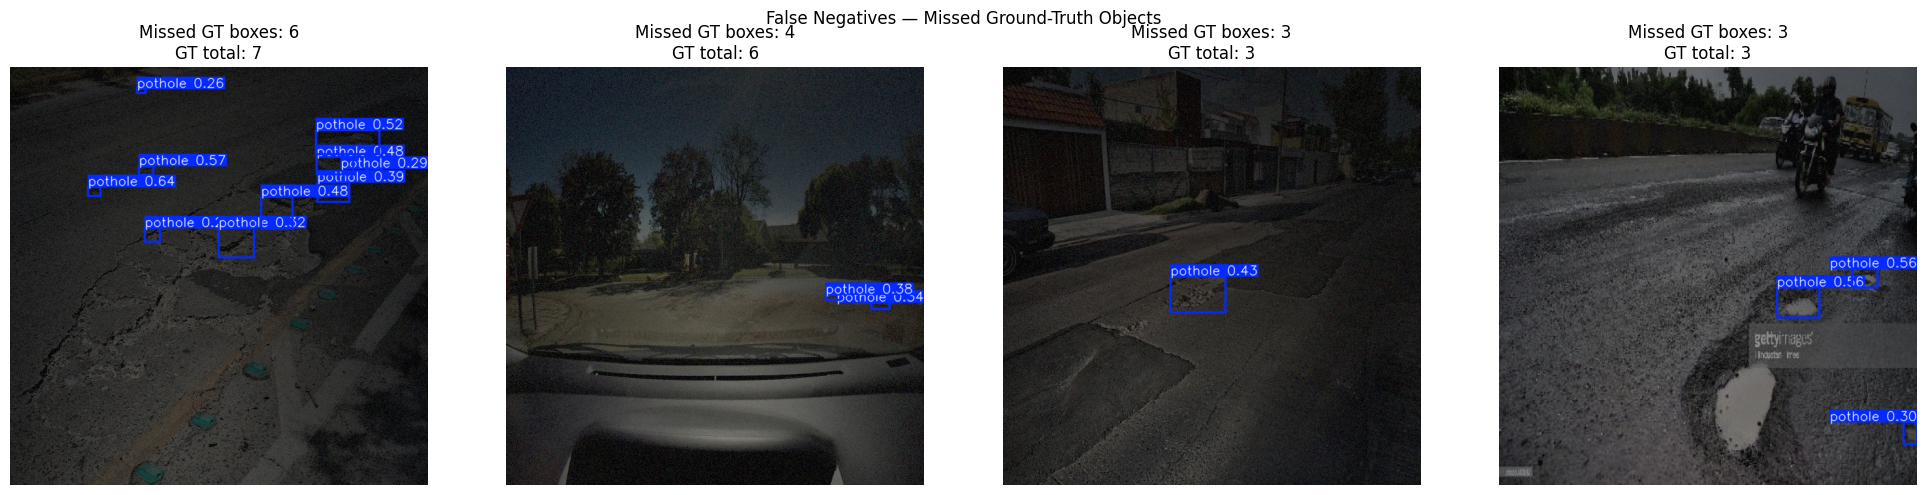

False-negative visualization saved to: /content/nighttime-pothole-detection/error_analysis_fn.png


In [ ]:

# ============================================================
# CELL 11: Error Analysis — False Positives and False Negatives
# ============================================================

from pathlib import Path
import random
import numpy as np
import matplotlib.pyplot as plt
import yaml

# Load dataset configuration
with open(data_yaml_path, "r") as f:
    cfg = yaml.safe_load(f)

# Select evaluation split
eval_split = "test" if cfg.get("test") else "val"
eval_img_dir = Path(cfg[eval_split])

# Resolve relative image paths
if not eval_img_dir.is_absolute():
    dataset_base = Path(cfg.get("path", Path(data_yaml_path).parent))
    eval_img_dir = dataset_base / eval_img_dir

# Find corresponding labels directory
if eval_img_dir.name == "images":
    eval_lbl_dir = eval_img_dir.parent / "labels"
elif "images" in eval_img_dir.parts:
    parts = list(eval_img_dir.parts)
    parts[parts.index("images")] = "labels"
    eval_lbl_dir = Path(*parts)
else:
    raise ValueError(
        f"Cannot infer labels directory from {eval_img_dir}. "
        "Please set eval_lbl_dir manually."
    )

print("Evaluation images:", eval_img_dir)
print("Ground-truth labels:", eval_lbl_dir)

# IoU calculation for boxes in xyxy format
def box_iou_xyxy(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    area1 = max(0, box1[2] - box1[0]) * max(0, box1[3] - box1[1])
    area2 = max(0, box2[2] - box2[0]) * max(0, box2[3] - box2[1])

    union = area1 + area2 - intersection
    return intersection / union if union > 0 else 0.0


def analyze_errors(model, img_dir, lbl_dir, n_samples=50, match_iou=0.5):
    """Match predicted boxes to ground truth using IoU and class IDs."""

    img_exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}
    imgs = [
        f for f in img_dir.iterdir()
        if f.is_file() and f.suffix.lower() in img_exts
    ]

    if not imgs:
        raise FileNotFoundError(f"No images found in {img_dir}")

    random.seed(42)
    sample = random.sample(imgs, min(n_samples, len(imgs)))

    false_positives = []
    false_negatives = []
    true_positives = []

    total_tp = total_fp = total_fn = 0

    for img_path in sample:
        lbl_path = lbl_dir / f"{img_path.stem}.txt"

        # Read YOLO ground-truth labels:
        # class_id, x_center, y_center, width, height
        gt_boxes = []
        gt_classes = []

        if lbl_path.exists():
            with open(lbl_path, "r") as f:
                for line in f:
                    parts = line.strip().split()
                    if len(parts) >= 5:
                        gt_classes.append(int(float(parts[0])))
                        gt_boxes.append([float(v) for v in parts[1:5]])

        # Convert normalized xywh to pixel xyxy
        from PIL import Image
        with Image.open(img_path) as im:
            width, height = im.size

        gt_xyxy = []
        for x, y, w, h in gt_boxes:
            gt_xyxy.append([
                (x - w / 2) * width,
                (y - h / 2) * height,
                (x + w / 2) * width,
                (y + h / 2) * height
            ])

        # Predict
        result = model.predict(
            source=str(img_path),
            imgsz=IMG_SIZE,
            conf=CONF_THRESH,
            iou=IOU_THRESH,
            device=DEVICE,
            verbose=False
        )[0]

        pred_boxes = []
        pred_classes = []

        if result.boxes is not None and len(result.boxes):
            pred_boxes = result.boxes.xyxy.cpu().numpy().tolist()
            pred_classes = result.boxes.cls.cpu().numpy().astype(int).tolist()

        # Greedy one-to-one matching, highest IoU first
        candidates = []

        for pi, pbox in enumerate(pred_boxes):
            for gi, gbox in enumerate(gt_xyxy):
                if pred_classes[pi] != gt_classes[gi]:
                    continue

                overlap = box_iou_xyxy(pbox, gbox)
                if overlap >= match_iou:
                    candidates.append((overlap, pi, gi))

        candidates.sort(reverse=True)

        matched_preds = set()
        matched_gts = set()

        for overlap, pi, gi in candidates:
            if pi not in matched_preds and gi not in matched_gts:
                matched_preds.add(pi)
                matched_gts.add(gi)

        tp = len(matched_preds)
        fp = len(pred_boxes) - tp
        fn = len(gt_xyxy) - len(matched_gts)

        total_tp += tp
        total_fp += fp
        total_fn += fn

        if fp:
            false_positives.append((img_path, fp, len(gt_xyxy)))
        if fn:
            false_negatives.append((img_path, fn, len(gt_xyxy)))
        if tp:
            true_positives.append((img_path, tp, len(gt_xyxy)))

    return (
        false_positives, false_negatives, true_positives,
        total_tp, total_fp, total_fn, len(sample)
    )


fps, fns, tps, total_tp, total_fp, total_fn, n_analyzed = analyze_errors(
    best_model,
    eval_img_dir,
    eval_lbl_dir,
    n_samples=50,
    match_iou=0.5
)

print("\n" + "=" * 55)
print(f"ERROR ANALYSIS — {eval_split.upper()} SET")
print("=" * 55)
print(f"Images analyzed:       {n_analyzed}")
print(f"True-positive boxes:   {total_tp}")
print(f"False-positive boxes:  {total_fp}")
print(f"False-negative boxes:  {total_fn}")

precision = total_tp / (total_tp + total_fp) if total_tp + total_fp else 0
recall = total_tp / (total_tp + total_fn) if total_tp + total_fn else 0

print(f"Sample precision:      {precision:.4f}")
print(f"Sample recall:         {recall:.4f}")
print("=" * 55)

# Visualize images with missed ground-truth detections
if fns:
    top_fns = sorted(fns, key=lambda item: item[1], reverse=True)[:4]

    fig, axes = plt.subplots(
        1, len(top_fns),
        figsize=(5 * len(top_fns), 5),
        squeeze=False
    )

    for ax, (img_path, missed, n_gt) in zip(axes.flat, top_fns):
        result = best_model.predict(
            source=str(img_path),
            imgsz=IMG_SIZE,
            conf=CONF_THRESH,
            iou=IOU_THRESH,
            device=DEVICE,
            verbose=False
        )[0]

        annotated = result.plot()
        ax.imshow(annotated[:, :, ::-1])
        ax.set_title(f"Missed GT boxes: {missed}\nGT total: {n_gt}")
        ax.axis("off")

    plt.suptitle("False Negatives — Missed Ground-Truth Objects")
    plt.tight_layout()

    fn_path = Path(OUTPUT_DIR) / "error_analysis_fn.png"
    plt.savefig(fn_path, dpi=150, bbox_inches="tight")
    plt.show()

    print("False-negative visualization saved to:", fn_path)
else:
    print("\nNo false negatives found in the sampled images at IoU 0.5.")


In [ ]:
# ============================================================
# CELL 12: Results Summary & Per-Class Breakdown
# ============================================================

import pandas as pd
import yaml
from pathlib import Path

# Load dataset configuration
with open(data_yaml_path, "r") as f:
    cfg = yaml.safe_load(f)

class_names = cfg.get(
    "names",
    ["crocodile crack", "longitudinal crack", "pothole"]
)

if isinstance(class_names, dict):
    class_names = [
        class_names[k] for k in sorted(class_names, key=lambda x: int(x))
    ]

# Helper: safely format metric values
def format_metric(value):
    try:
        return f"{float(value):.4f}"
    except (TypeError, ValueError):
        return "N/A"

# ============================================================
# Overall metrics from validation
# ============================================================

metrics = val_results.results_dict

# Epochs actually run (set in the training cell; falls back to EPOCHS if that cell wasn't run this session)
epochs_run = globals().get("EPOCHS_RUN", EPOCHS)

our_results = {
    "Experiment": f"Baseline YOLOv8{MODEL_SIZE}",
    "Dataset": Path(DATASET_PATH).name,
    "Classes": len(class_names),
    "Epochs": epochs_run,
    "Image Size": IMG_SIZE,
    "Batch Size": BATCH_SIZE,
    "Precision": format_metric(metrics.get("metrics/precision(B)")),
    "Recall": format_metric(metrics.get("metrics/recall(B)")),
    "mAP@0.5": format_metric(metrics.get("metrics/mAP50(B)")),
    "mAP@0.5:0.95": format_metric(metrics.get("metrics/mAP50-95(B)")),
}

# Literature reference values (not results from your experiment)
paper_yolov8 = {
    "Experiment": "Paper: YOLOv8 (NPD, 1-class)",
    "Dataset": "NPD",
    "Classes": 1,
    "Epochs": 300,
    "Image Size": "Not reported here",
    "Batch Size": 32,
    "Precision": "N/A",
    "Recall": "N/A",
    "mAP@0.5": "0.903",
    "mAP@0.5:0.95": "0.562",
}

paper_ref = {
    "Experiment": "Paper: WT-YOLOv8 (NPD, 1-class)",
    "Dataset": "NPD",
    "Classes": 1,
    "Epochs": 300,
    "Image Size": "Not reported here",
    "Batch Size": 32,
    "Precision": "N/A",
    "Recall": "N/A",
    "mAP@0.5": "0.918",
    "mAP@0.5:0.95": "0.585",
}

df = pd.DataFrame([our_results, paper_yolov8, paper_ref])

print("\n" + "=" * 100)
print("OVERALL RESULTS COMPARISON")
print("=" * 100)
print(df.to_string(index=False))

print("\nNOTE:")
print("- Your metrics are from your own validation run.")
print("- Paper values are reference figures, not your experimental results.")
print("- Direct comparison may be invalid due to differences in dataset,")
print("  classes, training setup, and model architecture.")
print("=" * 100)

# ============================================================
# Per-class AP breakdown
# ============================================================

print("\n" + "=" * 75)
print(f"PER-CLASS RESULTS — Baseline YOLOv8{MODEL_SIZE}")
print("=" * 75)

if hasattr(val_results, "box") and val_results.box is not None:
    ap50_values = val_results.box.ap50
    ap_values = val_results.box.ap

    for i, name in enumerate(class_names):
        ap50 = (
            ap50_values[i]
            if i < len(ap50_values)
            else None
        )
        ap = (
            ap_values[i]
            if i < len(ap_values)
            else None
        )

        print(
            f"[{i}] {str(name):25s} "
            f"AP@0.5: {format_metric(ap50)}  "
            f"AP@0.5:0.95: {format_metric(ap)}"
        )
else:
    print("Per-class AP is unavailable in the validation results.")

print("=" * 75)

# ============================================================
# Save results
# ============================================================

OUTPUT_DIR = Path(OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

csv_path = OUTPUT_DIR / "results_comparison.csv"
df.to_csv(csv_path, index=False)

print(f"\nResults CSV saved to: {csv_path}")


OVERALL RESULTS COMPARISON
                     Experiment      Dataset  Classes  Epochs        Image Size  Batch Size Precision Recall mAP@0.5 mAP@0.5:0.95
               Baseline YOLOv8n pothole_only        1     100               640           8    0.6995 0.5090  0.5854       0.2983
   Paper: YOLOv8 (NPD, 1-class)          NPD        1     300 Not reported here          32       N/A    N/A   0.903        0.562
Paper: WT-YOLOv8 (NPD, 1-class)          NPD        1     300 Not reported here          32       N/A    N/A   0.918        0.585

NOTE:
- Your metrics are from your own validation run.
- Paper values are reference figures, not your experimental results.
- Direct comparison may be invalid due to differences in dataset,
  classes, training setup, and model architecture.

PER-CLASS RESULTS — Baseline YOLOv8n
[0] pothole                   AP@0.5: 0.5854  AP@0.5:0.95: 0.2983

Results CSV saved to: /content/nighttime-pothole-detection/results_comparison.csv


In [ ]:

# ============================================================
# CELL 13: Save Outputs for Submission (Google Colab)
# ============================================================

from pathlib import Path
import shutil

OUTPUT_DIR = Path(OUTPUT_DIR)
results_dir = OUTPUT_DIR / "baseline"

# List all output files
print("Output files saved to:", OUTPUT_DIR)
print("-" * 60)

all_files = sorted(p for p in OUTPUT_DIR.rglob("*") if p.is_file())

if all_files:
    for f in all_files:
        size_kb = f.stat().st_size / 1024
        print(f"  {f.relative_to(OUTPUT_DIR)} ({size_kb:.1f} KB)")
else:
    print("No output files found.")

# Important files summary
important_files = {
    "Best model weights": results_dir / "weights" / "best.pt",
    "Last model weights": results_dir / "weights" / "last.pt",
    "Results CSV": OUTPUT_DIR / "results_comparison.csv",
    "Prediction samples": OUTPUT_DIR / "prediction_samples.png",
    "Training summary": OUTPUT_DIR / "training_summary.png",
    "Error analysis": OUTPUT_DIR / "error_analysis_fn.png",
}

print("\n" + "=" * 60)
print("IMPORTANT FILES")
print("=" * 60)

for label, path in important_files.items():
    status = "AVAILABLE" if path.is_file() else "NOT FOUND"
    print(f"{label}: {status}")
    if path.is_file():
        print(f"  Path: {path}")

# Package all results for download
ZIP_BASE = Path("/content/nighttime-pothole-submission")
ZIP_PATH = shutil.make_archive(
    str(ZIP_BASE),
    "zip",
    root_dir=str(OUTPUT_DIR)
)

print("\n" + "=" * 60)
print("SUBMISSION PACKAGE CREATED")
print("=" * 60)
print("ZIP file:", ZIP_PATH)
print(f"ZIP size: {Path(ZIP_PATH).stat().st_size / (1024**2):.2f} MB")

# Download the complete project outputs
from google.colab import files
files.download(ZIP_PATH)


Output files saved to: /content/nighttime-pothole-detection
------------------------------------------------------------
  baseline/BoxF1_curve.png (101.3 KB)
  baseline/BoxPR_curve.png (95.7 KB)
  baseline/BoxP_curve.png (98.6 KB)
  baseline/BoxR_curve.png (100.8 KB)
  baseline/args.yaml (1.7 KB)
  baseline/confusion_matrix.png (101.6 KB)
  baseline/confusion_matrix_normalized.png (96.9 KB)
  baseline/labels.jpg (168.4 KB)
  baseline/results.csv (11.8 KB)
  baseline/results.png (260.9 KB)
  baseline/train_batch0.jpg (504.3 KB)
  baseline/train_batch1.jpg (531.7 KB)
  baseline/train_batch2.jpg (462.6 KB)
  baseline/train_batch21150.jpg (379.5 KB)
  baseline/train_batch21151.jpg (406.4 KB)
  baseline/train_batch21152.jpg (401.4 KB)
  baseline/val_batch0_labels.jpg (637.9 KB)
  baseline/val_batch0_pred.jpg (636.8 KB)
  baseline/val_batch1_labels.jpg (804.0 KB)
  baseline/val_batch1_pred.jpg (808.9 KB)
  baseline/val_batch2_labels.jpg (601.4 KB)
  baseline/val_batch2_pred.jpg (630.8 KB)
 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>